#**Project Overview**

Wildfire is an important ecological process in Yosemite National Park, but historical burn patterns vary across the landscape. Understanding how terrain, land cover, and proximity to human infrastructure relate to historical burn occurrence can provide insight into the spatial patterns of wildfire across the park.

This project uses geospatial analysis and machine learning to model historical burn susceptibility across Yosemite National Park. Environmental and infrastructure data are integrated into a 500-meter analysis grid, and two classification algorithms, Logistic Regression and Random Forest, are evaluated using different spatial train/test splitting strategies.

The central research question is: How does spatial train/test methodology affect the evaluation of wildfire susceptibility models in Yosemite National Park?

By comparing random splits, spatial-block splits, geographic holdouts, and buffered geographic holdouts, this project investigates how model performance changes when test data become more geographically separated from training data. The results highlight the importance of spatial validation when evaluating machine learning models for geographic applications.

The final output is a GIS map of modeled historical burn susceptibility, visualizing estimated probabilities of historical burn occurrence across the study area.

Tools: Python, pandas, GeoPandas, scikit-learn, QGIS

Key concepts: Geospatial data processing, feature engineering, binary classification, spatial validation, model evaluation, and GIS visualization.

#**Data sources and preprocessing**

In order to study historical wildfire susceptibility across Yosemite National Park, land cover, elevation, historical fire perimeters, and human use data (trails, roads, and campsites) are aggregated into qGIS.

###Yosemite National Park boundary
The Yosemite National Park boundary line was obtained from an ArcGIS OpenData dataset. As areas surrounding the park have high human activity, many fires affecting the Yosemite region do not start within the bounds of the park, but spread from fires started in the near vicinity. Thus, a 25km buffer was added to create the study area.

###Historical Fire Perimeters
Historical fire perimeter data was obtained from CalFire and loaded into qGIS as a vector layer, then clipped to the buffered Yosemite boundary. This data represents previous occurances of fires in the area from 1908-2025.

###Land Cover
Land cover data was obtained from the Multi-Resolution Land Charicteristics (MRLC) Consortium. This data has labels for Open Water; Perennial Ice/Snow; Developed, Open Space; Developed, Low Intensity; Developed, Medium Intensity; Developed, High Intensity; Barren Land Deciduous Forest; Evergreen Forest; Mixed Forest; Shrub/Scrub; Grassland/Herbaceous; Pasture/Hay; Cultivated Crops; Woody Wetlands; and Emergent Herbaceous Wetlands. This data for the whole California region was loaded as a vector layer into qGIS and clipped with the buffered Yosemite boundary.


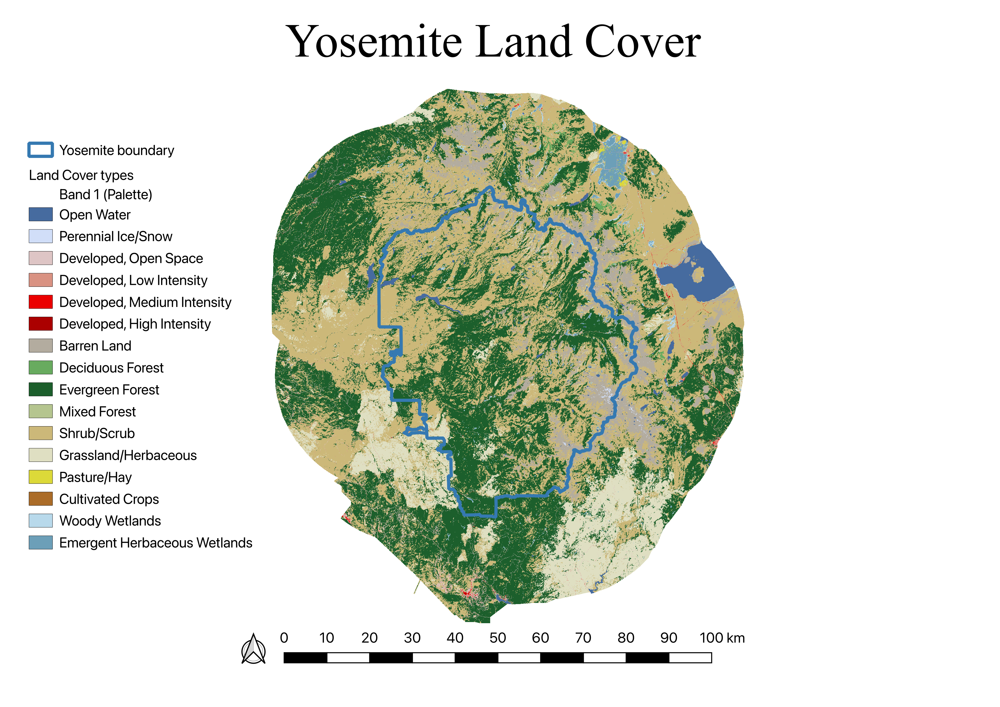

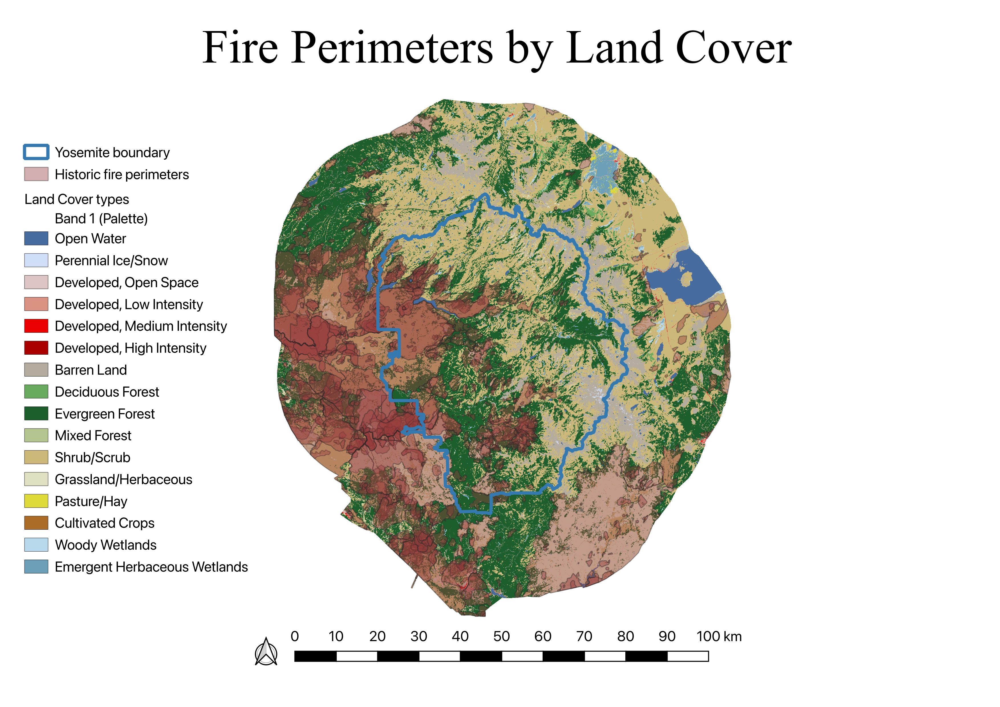

In [5]:
from IPython.display import Image, display

display(Image('landcover.png', width=500))
display(Image('landcover_fire_perimeters.png', width=500))

###Elevation
Elevation data was obtained from USGS in the form of DEM files. 6 different DEM files encompassing the Yosemite region were combined into a single raster layer in qGIS, then clipped to the buffered Yosemite boundary. From the elevation data, slope and aspect (compass direction that a terrain slope faces) were derived. These fields open up questions of whether steeper slopes or faces subject to more sunlight are more susceptible to burning and the spreading of wildfires.

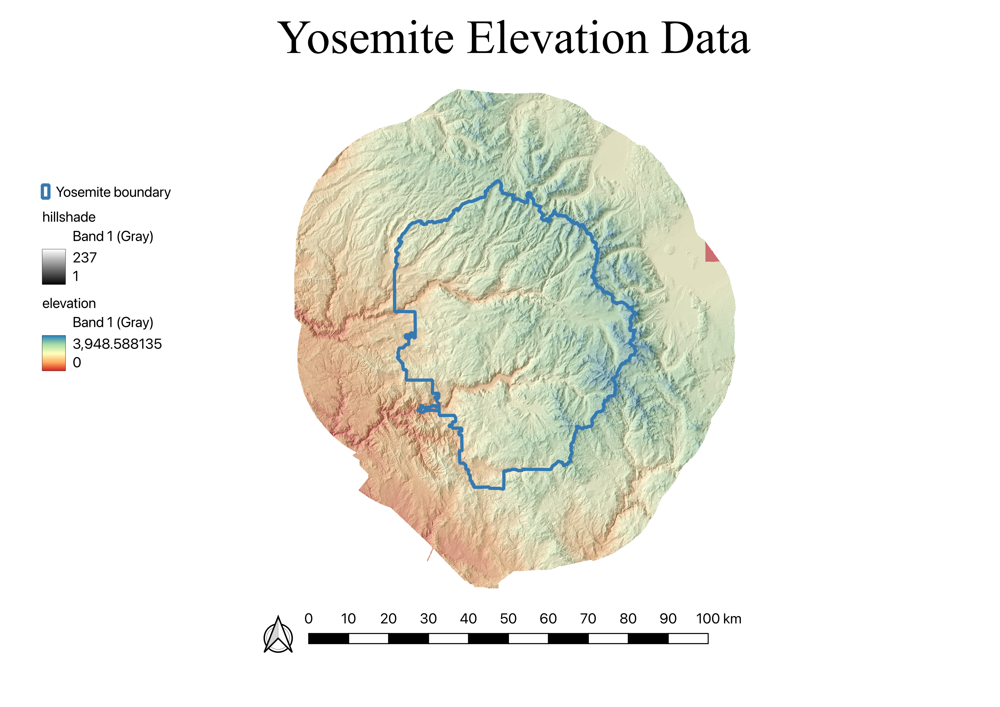

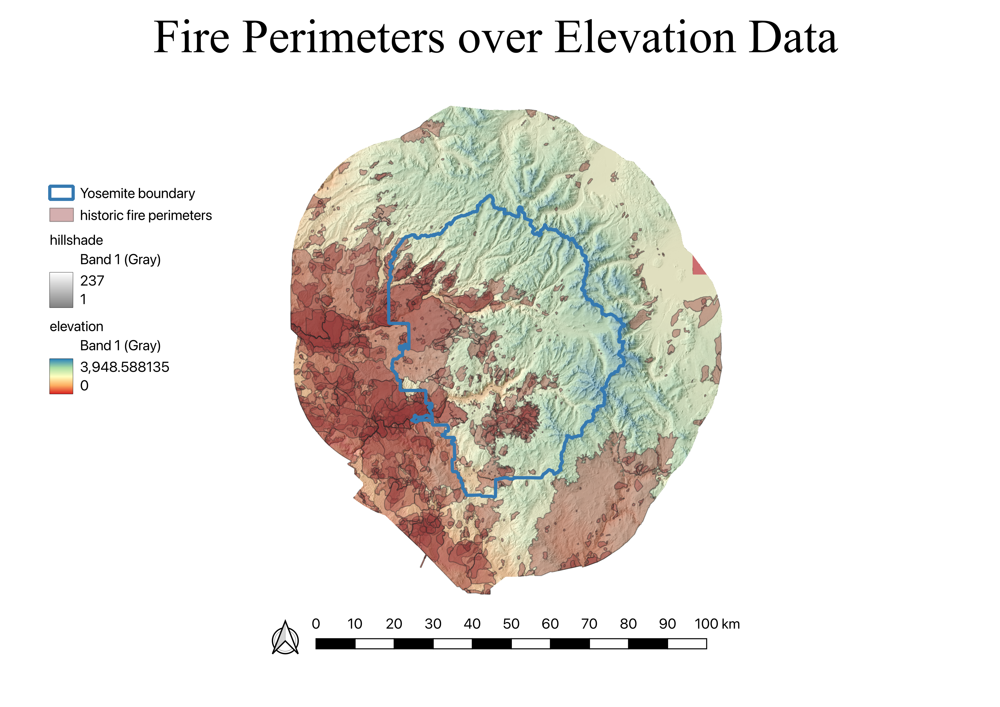

In [6]:
display(Image('elevation.png', width=500))
display(Image('elevation_fire_perimeters.png', width=500))

In the above maps, elevation data is displayed with hillshade (3D shading simulating sunlight and angles derived from the aspect layer) overlayed ontop . The majority of fire concentration appears at lower elevations, clustered more towards the lower-elevation west side of the park.

###Human Activity
Human activity data was obtained from OpenStreetMap. Data for the distance to the nearest roads, trails, and campsites was loaded into qGIS as vector layers. Similar data on parking lots, information centers, and picnic areas was also considered, but for simplicity sake was not included in this project. Future explorations may consider using this data.

###Creation of the 500-Meter Analysis Grid

A 500 m × 500 m grid was created across the study area to provide a consistent spatial framework for data integration and machine learning. Each cell represents an area of 250,000 m² (0.25 km²) and serves as an individual observation in the modeling dataset.

Environmental and infrastructure variables were associated with each grid cell, including elevation, slope, aspect, land-cover classification, and distances to roads, trails, and campsites. Historical fire perimeters were used to assign a binary target variable, `burned`, indicating whether a cell intersected a recorded historical fire perimeter (`1`) or did not (`0`).

Using a consistent grid resolution allowed datasets with different spatial formats and resolutions to be combined into a single structured dataset suitable for classification. Each cell could then be represented by its predictor variables and burn-occurrence label, allowing Logistic Regression and Random Forest to estimate the relationship between landscape characteristics and historical burning.

The 500 m resolution was selected as a practical balance between spatial detail and computational efficiency. However, it also introduces some limitations: individual cells may contain multiple land-cover types or partially intersect fire perimeters, and results may vary with grid resolution and alignment. The binary target represents recorded historical fire-perimeter intersection rather than the probability, severity, or frequency of burning. Consequently, the model estimates historical burn susceptibility at the grid-cell level rather than predicting future wildfire occurrence.


In [92]:
import pandas as pd
import numpy as np

In [7]:
df = pd.read_csv('analysis_points_burned.csv')

In [8]:
land_cover = {
    11: "Open Water",
    12: "Perennial Ice/Snow",
    21: "Developed, Open Space",
    22: "Developed, Low Intensity",
    23: "Developed, Medium Intensity",
    24: "Developed, High Intensity",
    31: "Barren Land",
    41: "Deciduous Forest",
    42: "Evergreen Forest",
    43: "Mixed Forest",
    52: "Shrub/Scrub",
    71: "Grassland/Herbaceous",
    81: "Pasture/Hay",
    82: "Cultivated Crops",
    90: "Woody Wetlands",
    85: "Emergent Herbaceous Wetlands"

}

In [10]:
#map land cover names to codes for easier plot labeling
df['Land Cover'] = df['nlcd1'].map(land_cover)

###Feature Distributions

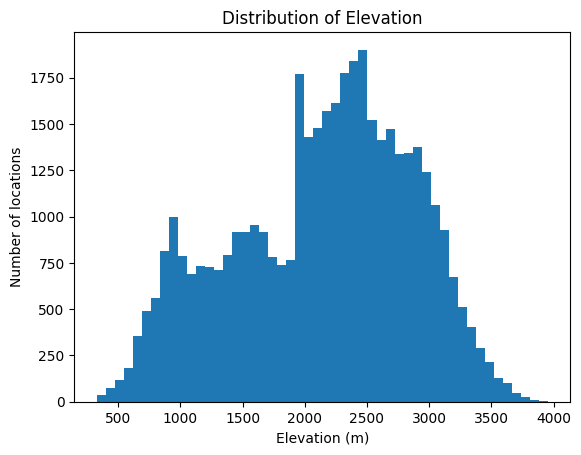

In [11]:
import matplotlib.pyplot as plt

plt.hist(df["elevation1"], bins=50)
plt.xlabel("Elevation (m)")
plt.ylabel("Number of locations")
plt.title("Distribution of Elevation")
plt.show()

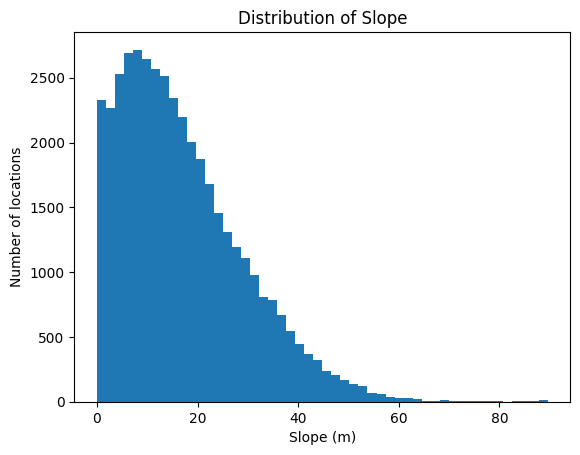

In [12]:
plt.hist(df["slope1"], bins=50)
plt.xlabel("Slope (m)")
plt.ylabel("Number of locations")
plt.title("Distribution of Slope")
plt.show()

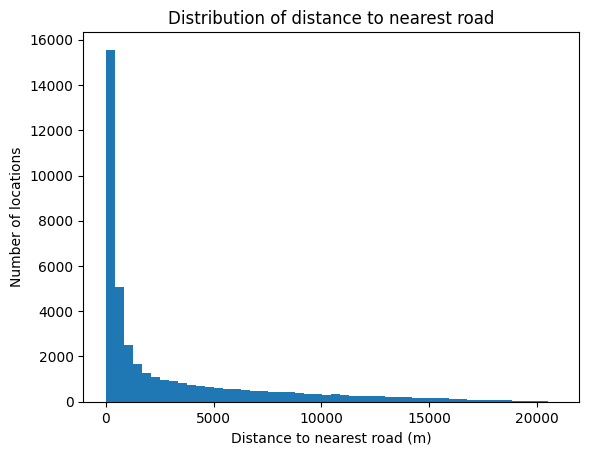

In [13]:
plt.hist(df["distance_road"], bins=50)
plt.xlabel("Distance to nearest road (m)")
plt.ylabel("Number of locations")
plt.title("Distribution of distance to nearest road")
plt.show()

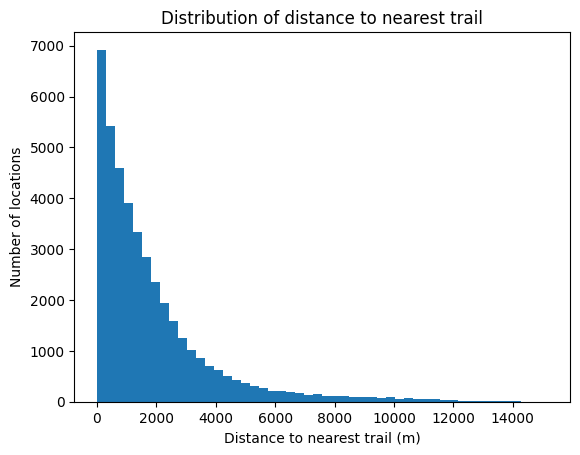

In [14]:
plt.hist(df["distance_path"], bins=50)
plt.xlabel("Distance to nearest trail (m)")
plt.ylabel("Number of locations")
plt.title("Distribution of distance to nearest trail")
plt.show()

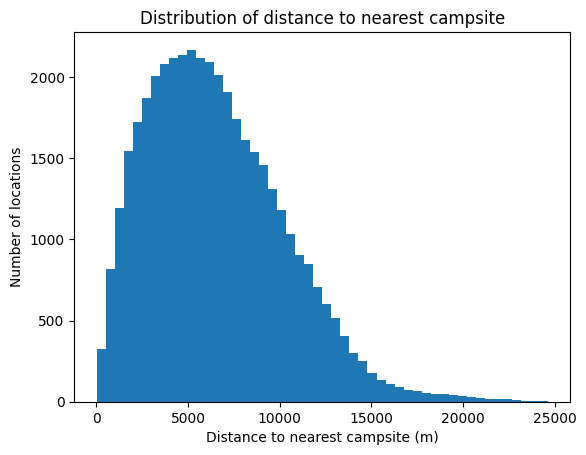

In [15]:
plt.hist(df["distance_campsite"], bins=50)
plt.xlabel("Distance to nearest campsite (m)")
plt.ylabel("Number of locations")
plt.title("Distribution of distance to nearest campsite")
plt.show()

###Burn rates by features

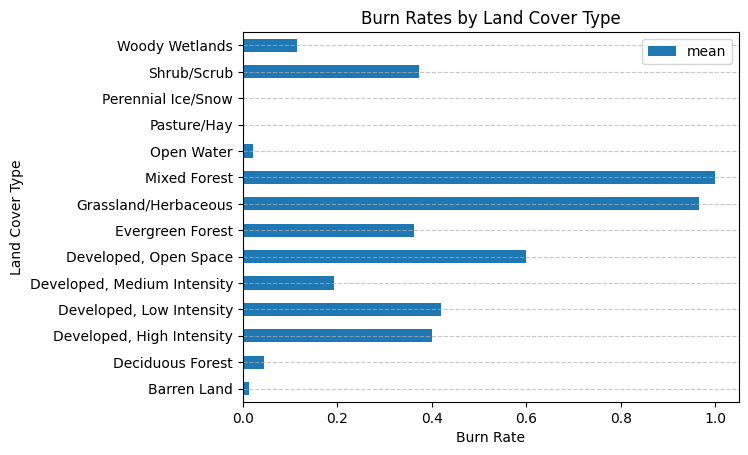

In [16]:
#mean is proportion burned
land_cover_burn_rates = df.groupby("Land Cover")["burned"].agg(["count", "mean"])
#burn rate by land cover type bar chart
land_cover_burn_rates.plot(y= 'mean', kind='barh', rot=0)
plt.title('Burn Rates by Land Cover Type')
plt.xlabel('Burn Rate')
plt.ylabel('Land Cover Type')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the chart
plt.show()

Mixed forest and grassland/herbaceous show the highest burn rates, while perennial ice/snow and pasture/hay show a rate of zero. While the burn rates represent an average of burn ocurrances, prevalence of land cover type in the area must still be considered.

In [17]:
#separate elevation into 10 bins
df["elevation_bin"] = pd.qcut(df["elevation1"], 10)

elevation_burn_rates = df.groupby("elevation_bin", observed=True)["burned"].mean()

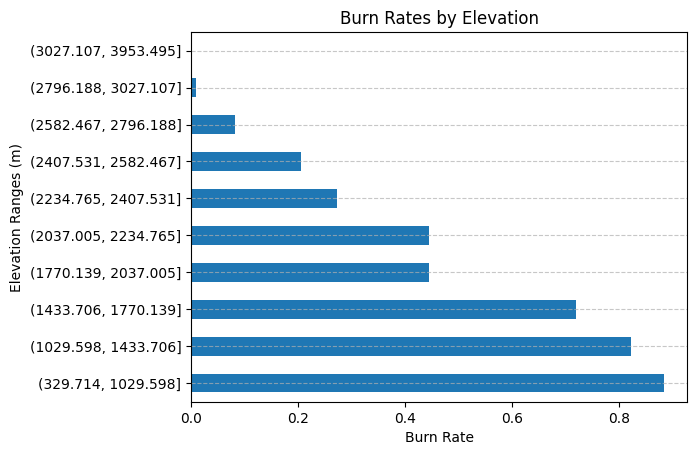

In [18]:
#burn rate by elevation bar chart
elevation_burn_rates.plot(y= 'burned', kind='barh', rot=0)
plt.title('Burn Rates by Elevation')
plt.xlabel('Burn Rate')
plt.ylabel('Elevation Ranges (m)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the chart
plt.show()

With each increased elevation bin, burn rates diminish, showing an inverse relationship between the two.

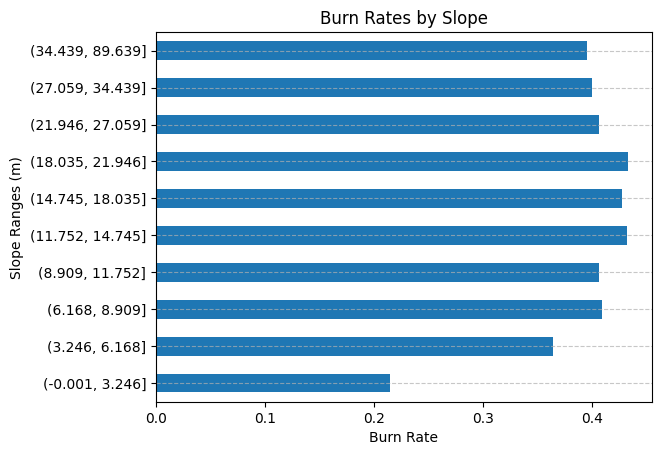

In [14]:
df["slope_bin"] = pd.qcut(df["slope1"], 10)

slope_burn_rates = df.groupby("slope_bin", observed=True)["burned"].mean()
#burn rate by slope bar chart
slope_burn_rates.plot(y= 'burned', kind='barh', rot=0)
plt.title('Burn Rates by Slope')
plt.xlabel('Burn Rate')
plt.ylabel('Slope Ranges (m)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the chart
plt.show()

Less of a difinitive relationship between slope and burn rates can be discerned. A very low slope shows the lowest burn rate, but as slopes increase, burn rates remain similar.

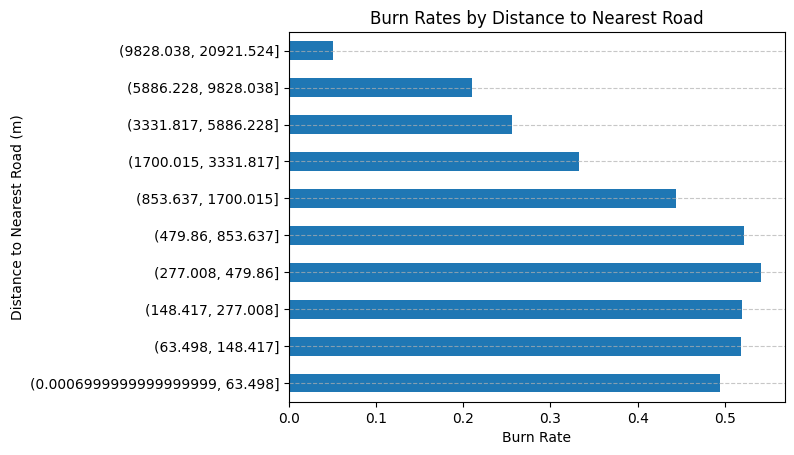

In [15]:
df["road_bin"] = pd.qcut(df["distance_road"], 10)

road_burn_rates = df.groupby("road_bin", observed=True)["burned"].mean()

#burn rate by distance to nearest road bar chart
road_burn_rates.plot(y= 'burned', kind='barh', rot=0)
plt.title('Burn Rates by Distance to Nearest Road')
plt.xlabel('Burn Rate')
plt.ylabel('Distance to Nearest Road (m)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the chart
plt.show()

Burn rates appear similar for the lower half of distances to the nearest road, and begin to drop significantly once distances become large.

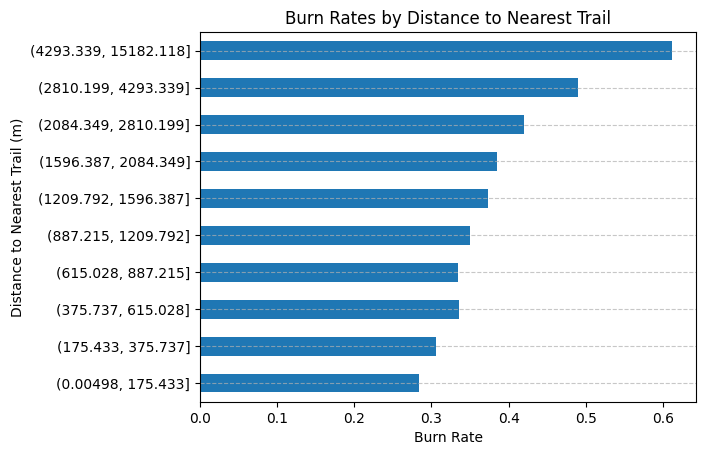

In [16]:
df["trail_bin"] = pd.qcut(df["distance_path"], 10)

trail_burn_rates = df.groupby("trail_bin", observed=True)["burned"].mean()
#burn rate by distance to nearest trail bar chart
trail_burn_rates.plot(y= 'burned', kind='barh', rot=0)
plt.title('Burn Rates by Distance to Nearest Trail')
plt.xlabel('Burn Rate')
plt.ylabel('Distance to Nearest Trail (m)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the chart
plt.show()

Surprisingly, unlike the distance to the nearest road, as distances to the nearest trail increase burn rates also increase.

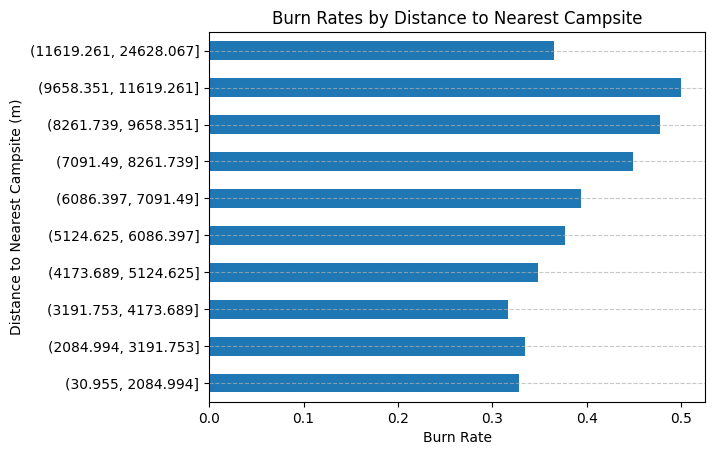

In [17]:
df["campsite_bin"] = pd.qcut(df["distance_campsite"], 10)

campsite_burn_rates = df.groupby("campsite_bin", observed=True)["burned"].mean()

#burn rate by distance to nearest campsite bar chart
campsite_burn_rates.plot(y= 'burned', kind='barh', rot=0)
plt.title('Burn Rates by Distance to Nearest Campsite')
plt.xlabel('Burn Rate')
plt.ylabel('Distance to Nearest Campsite (m)')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the chart
plt.show()

For distance to nearest campsite, no definitive relationship to burn rates can be seen.

##**Geospatial Train/Test Split methods**

In many machine learning applications, a simple random train/test split is perfectly adequate. When working with geospatial data, however, performing a random split can have adverse affects on model training. This is because geospatial data is affected by spatial autocorrelation, meaning geospatial points nearby each other share similar values and environmental conditions. Thus, performing a random split places geospatially similar points in the training and testing sets, allowing for information leakage and the model to "cheat" by memorizing characteristics of geospatially similar points. For this project, 4 different train/test splits are explored.

1) First, the classic random split is used to establish a baseline and explore how to above described negative effects manifest with our wildfire data.

2) Second, spatial blocking is used to cluster similar geospatial points together to avoid significant information leakage between the training and testing set.

3) Third, a geographic holdout split is created in which the eastern 20% of the study area is used as the test set and the western 80% is used as the train set. The eastern area of the park is very geographically different than the western area, with elevations increasing dramatically and a different landscape emerging. With this split, the question of whether the model can generalize to a very different geographic area is explored.

4) Finally, a 10km buffer is added to the geographic holdout split. With this added buffer, the train and test sets remain completely separate, with no points next to each other between the sets.

In [20]:
from sklearn.model_selection import train_test_split

In [23]:
df["x"] = (df["left"] + df["right"]) / 2
df["y"] = (df["bottom"] + df["top"]) / 2

In [24]:
#plot the split helper function
def plot_split(x_train, y_train, x_test, y_test, split):
  plt.figure(figsize=(10, 8))
  plt.scatter(
      x_train,
      y_train,
      s=5,
      label="Training"
      )

  plt.scatter(
      x_test,
      y_test,
      s=5,
      label="Testing"
      )

  plt.xlabel("X coordinate (m)")
  plt.ylabel("Y coordinate (m)")
  plt.title(split + " Train/Test Split")
  plt.legend()
  plt.show()

In [27]:
#plot distributions helper function
def plot_dist(x_train, x_test, field, title, split):
  #plot train test elevations
  plt.figure(figsize=(10, 6))
  plt.hist(
      x_train[field],
      bins=40,
      alpha=0.6,
      label="Training"
      )

  plt.hist(
      x_test[field],
      bins=40,
      alpha=0.6,
      label="Testing"
      )

  plt.xlabel(title + " (m)")
  plt.ylabel("Number of grid cells")
  plt.title(title + " Distribution: " + split + " Training vs Testing")
  plt.legend()
  plt.show()

###Random Split

In [25]:
#randomly split into training and testing
X = df.drop(columns=['burned'])
y = df['burned']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

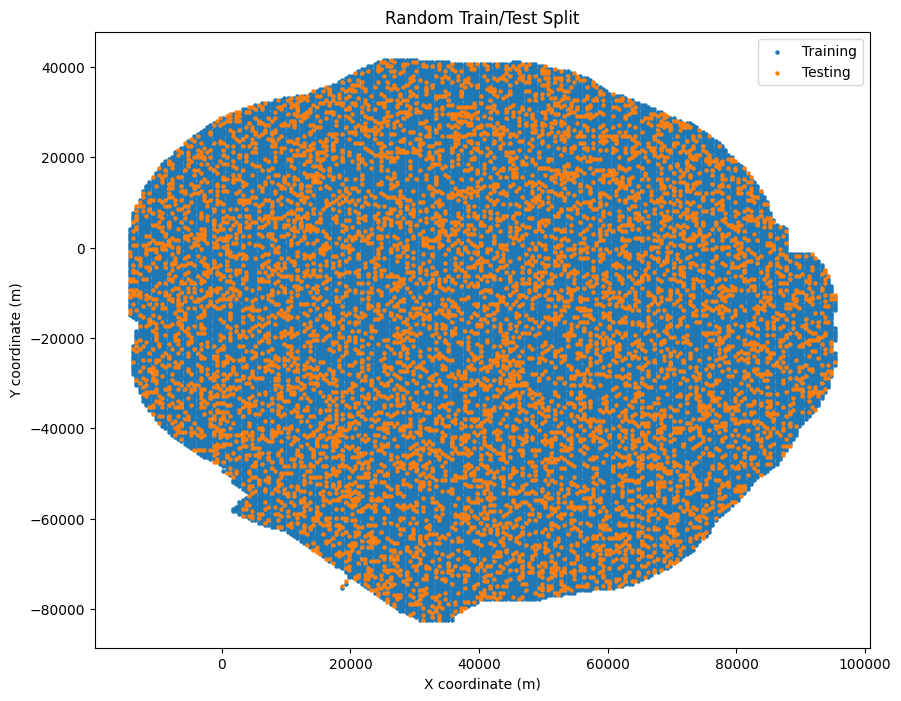

In [26]:
plot_split(X_train['x'], X_train['y'], X_test['x'], X_test['y'], "Random")

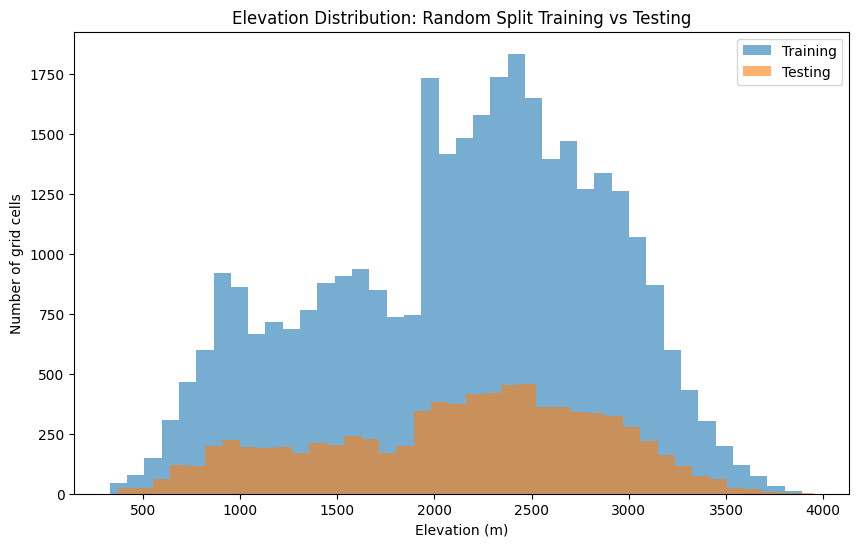

In [28]:
plot_dist(X_train, X_test, "elevation1", "Elevation", "Random Split")

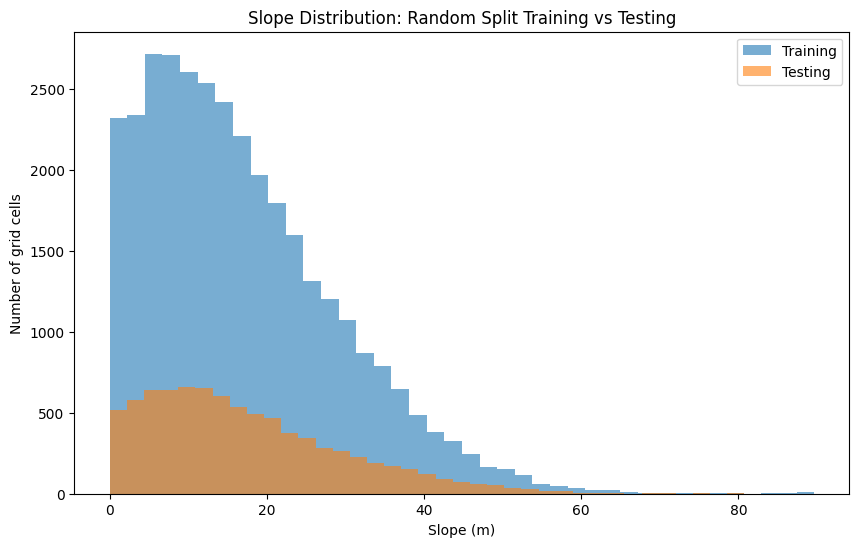

In [29]:
plot_dist(X_train, X_test, "slope1", "Slope", "Random Split")

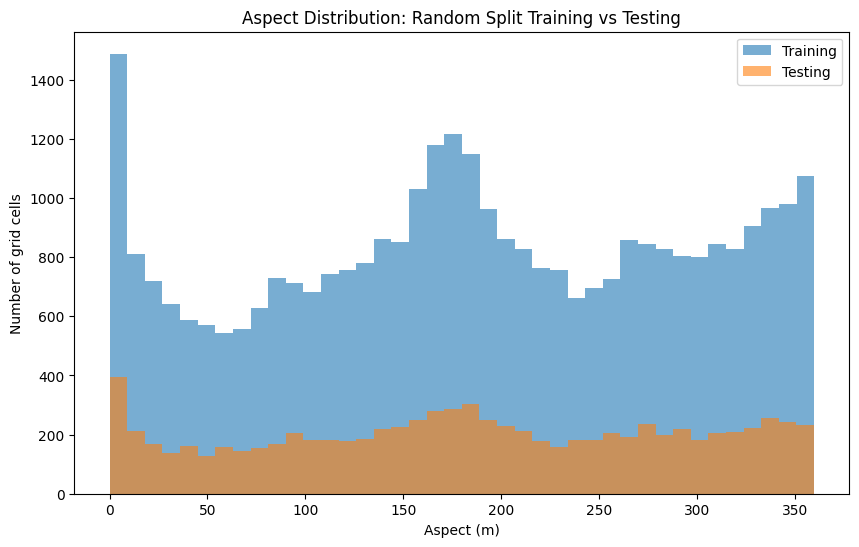

In [30]:
plot_dist(X_train, X_test, "aspect1", "Aspect", "Random Split")

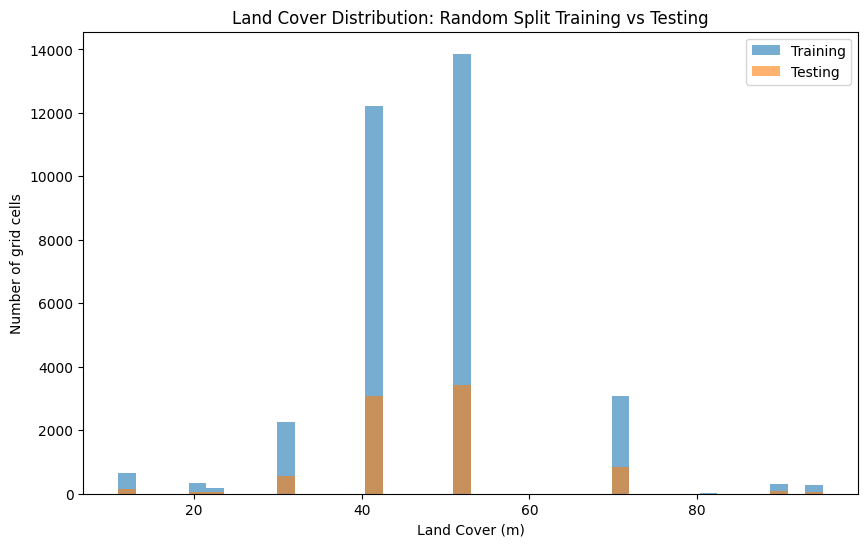

In [31]:
plot_dist(X_train, X_test, "nlcd1", "Land Cover", "Random Split")

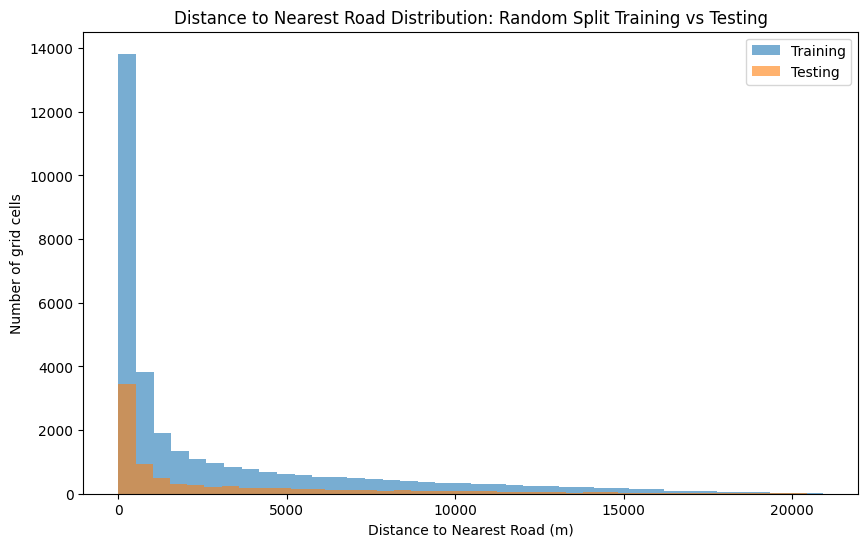

In [32]:
plot_dist(X_train, X_test, "distance_road", "Distance to Nearest Road", "Random Split")

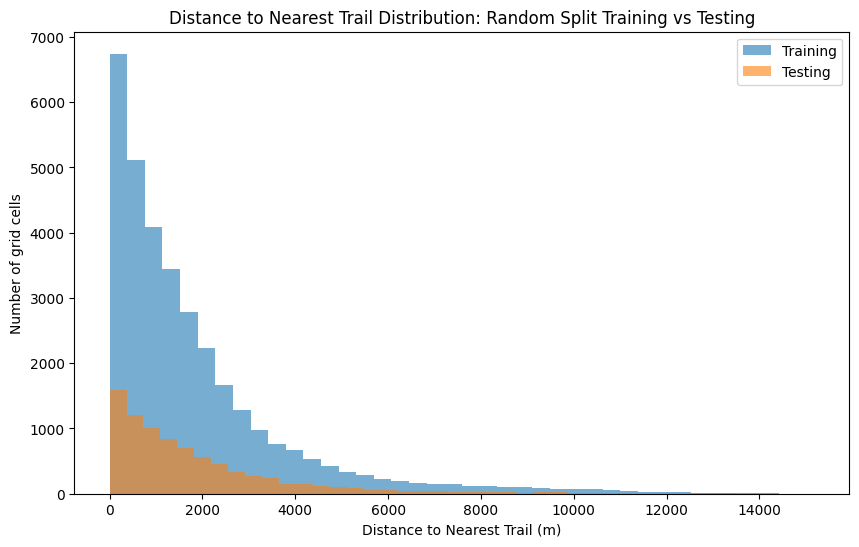

In [33]:
plot_dist(X_train, X_test, "distance_path", "Distance to Nearest Trail", "Random Split")

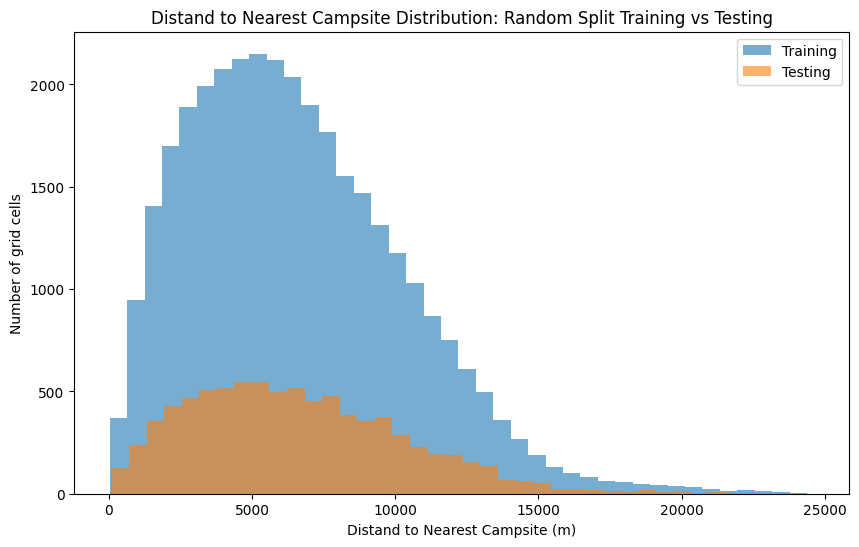

In [34]:
plot_dist(X_train, X_test, "distance_campsite", "Distand to Nearest Campsite", "Random Split")

As shown in the feature distributions, the training and test sets have very similar values across the predictor variables. While this indicates that both sets represent a similar range of environmental conditions, it also highlights a limitation of the random split for evaluating how well the model generalizes to geographically unseen areas. Because observations are randomly assigned to each set, nearby grid cells with similar terrain, land cover, and proximity to roads or trails may appear in both the training and test data. These spatial similarities can allow the model to perform well by learning patterns that are specific to the sampled area, potentially resulting in overly optimistic performance estimates. Although similar feature distributions do not necessarily indicate overfitting on their own, they suggest that the random split may not adequately test the model's ability to generalize to new geographic regions with different environmental characteristics. This motivates the use of spatially separated validation methods, which provide a more rigorous assessment of model performance beyond the areas represented in the training data.

###Spatial Blocking

In [35]:
# create blocks of 10x10 cells
df["block_row"] = df["row_index"] // 10
df["block_col"] = df["col_index"] // 10
# create unique block IDs
df["block_id"] = (
    df["block_row"].astype(str) + "_" +
    df["block_col"].astype(str)
)

In [36]:
blocks = df["block_id"].unique()

train_blocks, test_blocks = train_test_split(
    blocks,
    test_size=0.20,
    random_state=42
)

In [37]:
train_df_blocks = df[df["block_id"].isin(train_blocks)].copy()
test_df_blocks = df[df["block_id"].isin(test_blocks)].copy()

In [38]:
X_train_blocks = train_df_blocks.drop(columns=['burned'])
y_train_blocks = train_df_blocks['burned']
X_test_blocks = test_df_blocks.drop(columns=['burned'])
y_test_blocks = test_df_blocks['burned']

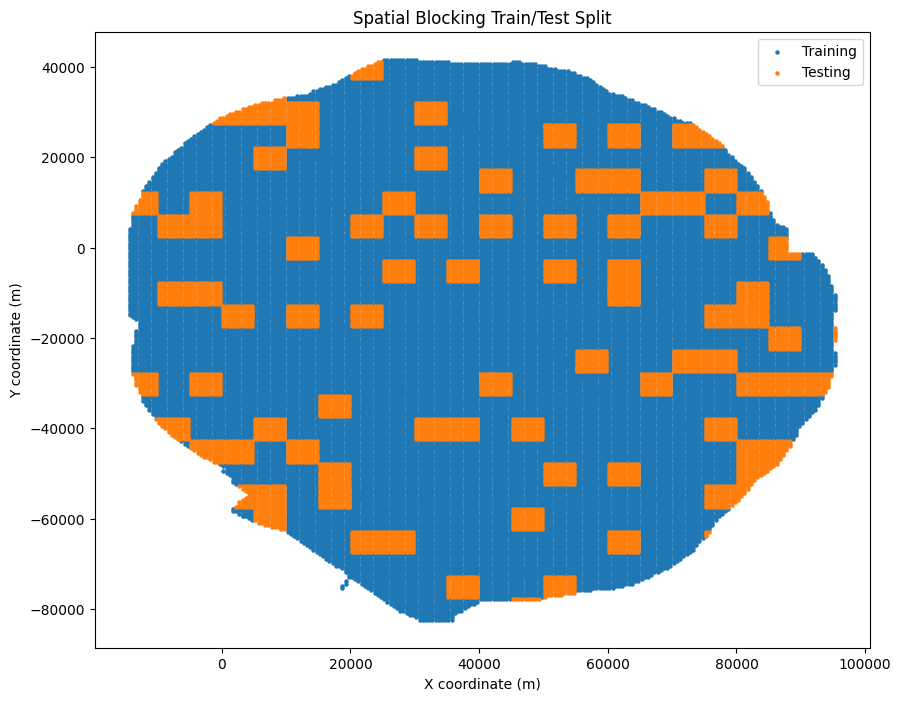

In [39]:
plot_split(train_df_blocks["x"], train_df_blocks["y"], test_df_blocks["x"], test_df_blocks["y"], "Spatial Blocking")

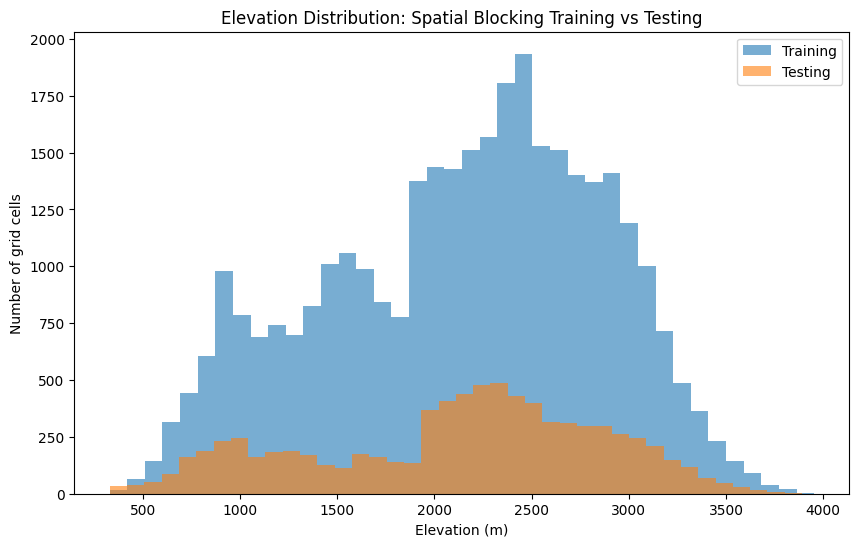

In [40]:
plot_dist(train_df_blocks, test_df_blocks, "elevation1", "Elevation", "Spatial Blocking")

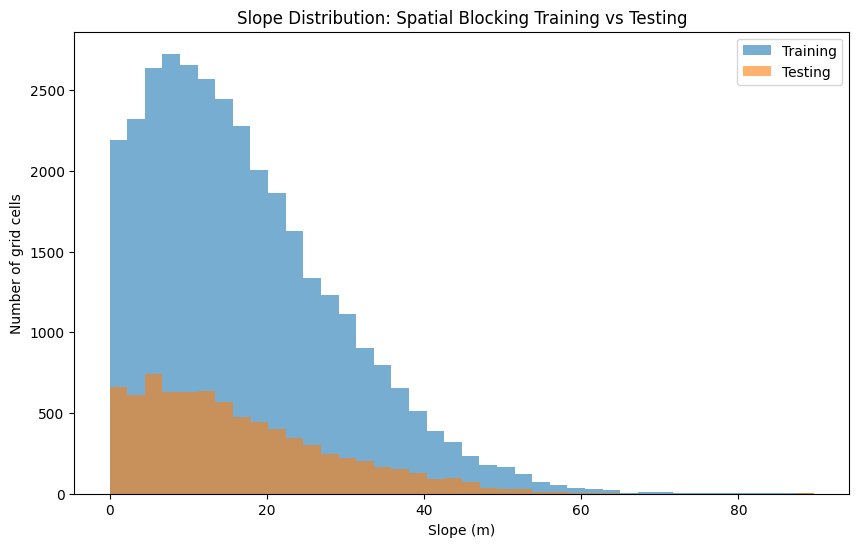

In [41]:
plot_dist(train_df_blocks, test_df_blocks, "slope1", "Slope", "Spatial Blocking")

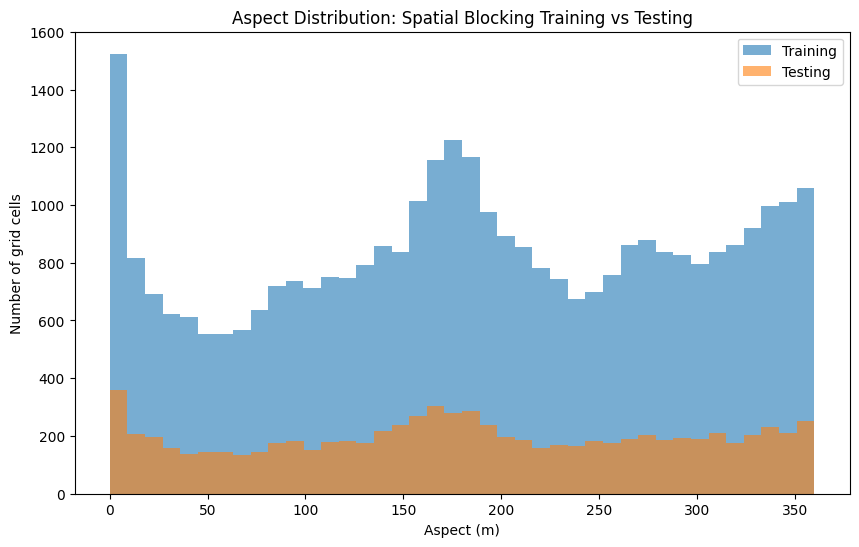

In [42]:
plot_dist(train_df_blocks, test_df_blocks, "aspect1", "Aspect", "Spatial Blocking")

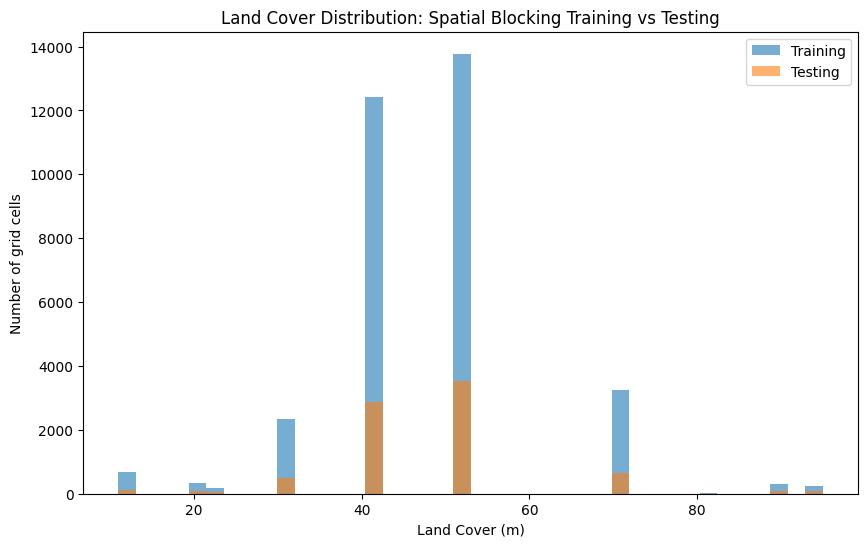

In [43]:
plot_dist(train_df_blocks, test_df_blocks, "nlcd1", "Land Cover", "Spatial Blocking")

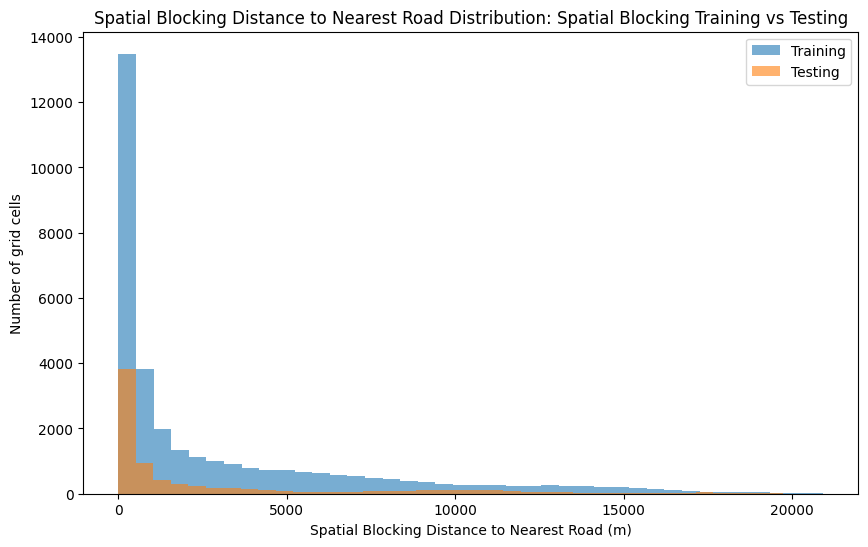

In [44]:
plot_dist(train_df_blocks, test_df_blocks, "distance_road", "Spatial Blocking Distance to Nearest Road", "Spatial Blocking")

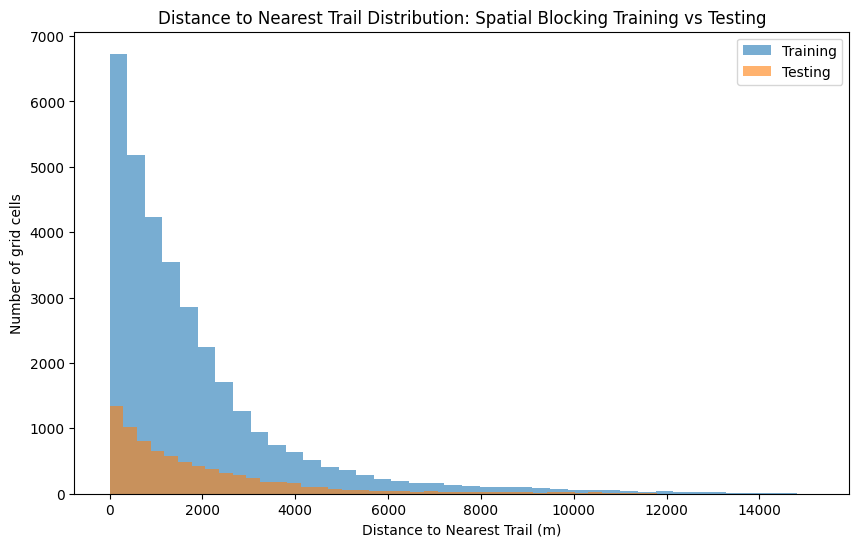

In [45]:
plot_dist(train_df_blocks, test_df_blocks, "distance_path", "Distance to Nearest Trail", "Spatial Blocking")

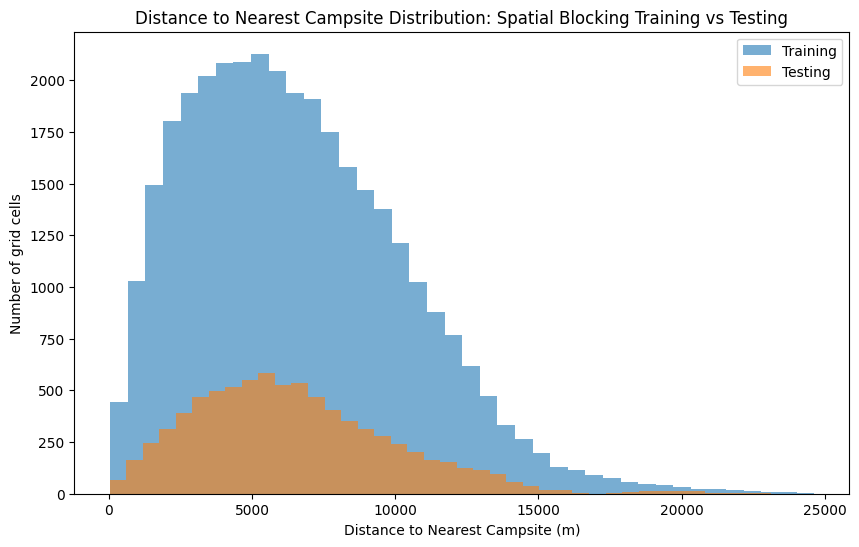

In [46]:
plot_dist(train_df_blocks, test_df_blocks, "distance_campsite", "Distance to Nearest Campsite", "Spatial Blocking")

The feature distributions for the spatial-block split appear similar between the training and test sets, much like those of the random split. This is likely because the spatial blocks are distributed across the study area, allowing both sets to represent a similar range of environmental conditions. Although entire blocks are assigned to one set to reduce spatial proximity between training and test observations, the split does not necessarily create a strong geographic or environmental separation. Consequently, similar feature distributions can coexist with reduced spatial dependence between the sets.

###Geospatial Holdout

In [47]:
#split into training and testing based on perimeter line
cutoff = df["x"].quantile(0.80)

print("Cutoff:", cutoff)

train_df_holdout = df[df["x"] < cutoff]
test_df_holdout = df[df["x"] >= cutoff]

print("\nTraining:")
print(len(train_df_holdout))
print(train_df_holdout["burned"].value_counts(normalize=True))

print("\nTesting:")
print(len(test_df_holdout))
print(test_df_holdout["burned"].value_counts(normalize=True))

Cutoff: 65739.2697

Training:
33106
burned
0    0.565215
1    0.434785
Name: proportion, dtype: float64

Testing:
8438
burned
0    0.790946
1    0.209054
Name: proportion, dtype: float64


In [48]:
X_train_holdout = train_df_holdout.drop(columns=['burned'])
y_train_holdout = train_df_holdout['burned']
X_test_holdout = test_df_holdout.drop(columns=['burned'])
y_test_holdout = test_df_holdout['burned']

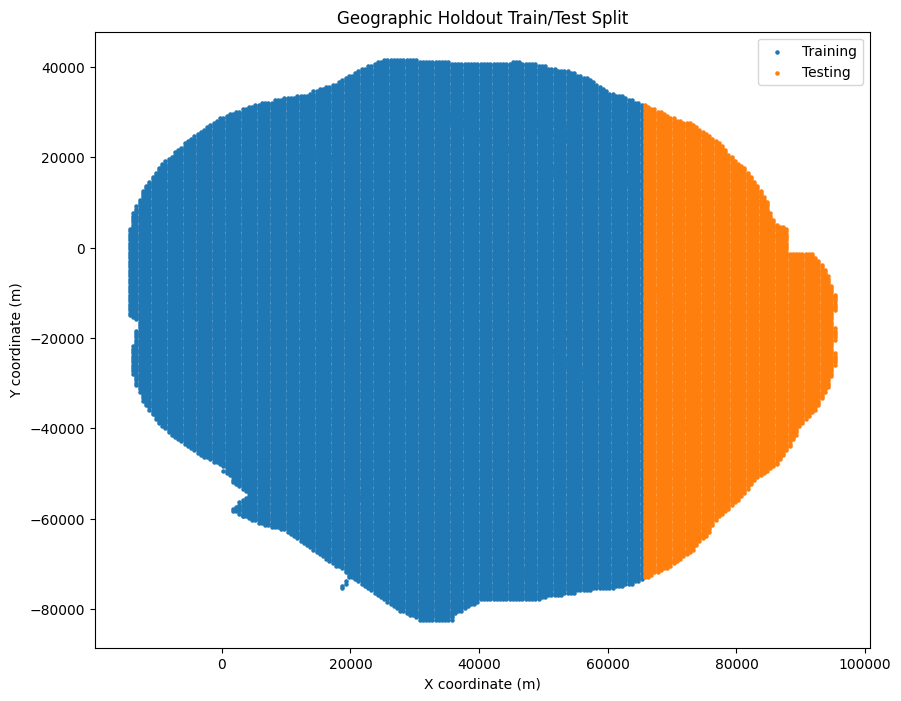

In [49]:
plot_split(train_df_holdout["x"], train_df_holdout["y"], test_df_holdout["x"], test_df_holdout["y"], "Geographic Holdout")

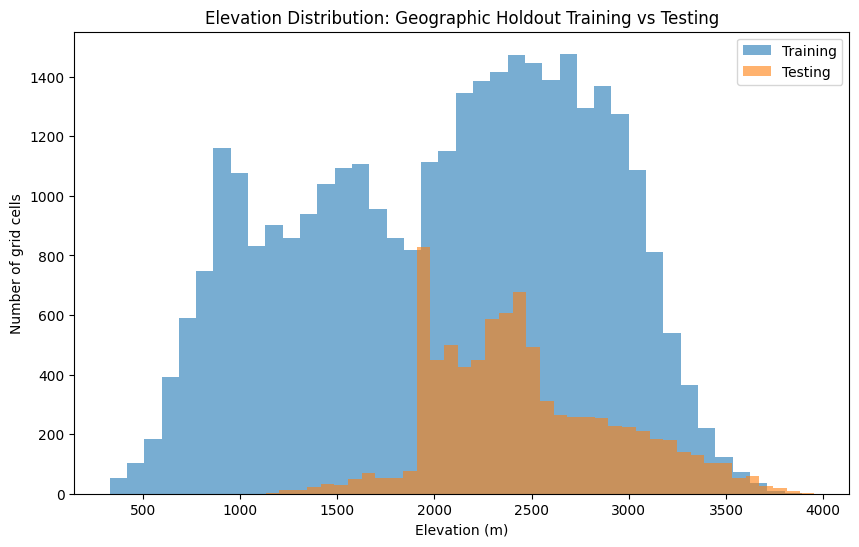

In [50]:
plot_dist(train_df_holdout, test_df_holdout, "elevation1", "Elevation", "Geographic Holdout")

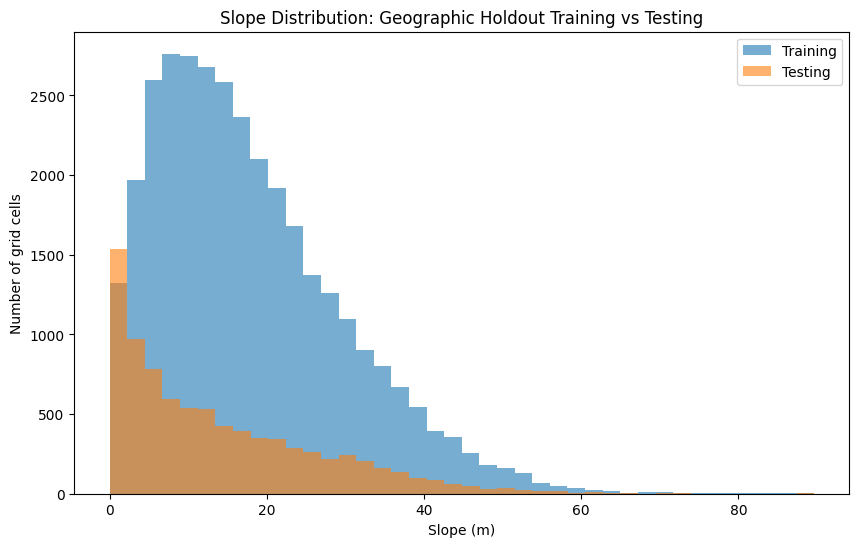

In [51]:
plot_dist(train_df_holdout, test_df_holdout, "slope1", "Slope", "Geographic Holdout")

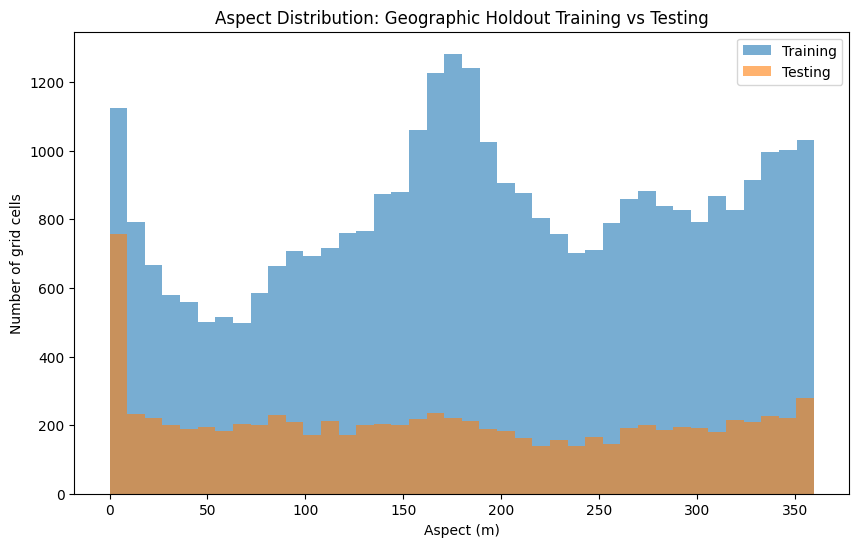

In [52]:
plot_dist(train_df_holdout, test_df_holdout, "aspect1", "Aspect", "Geographic Holdout")

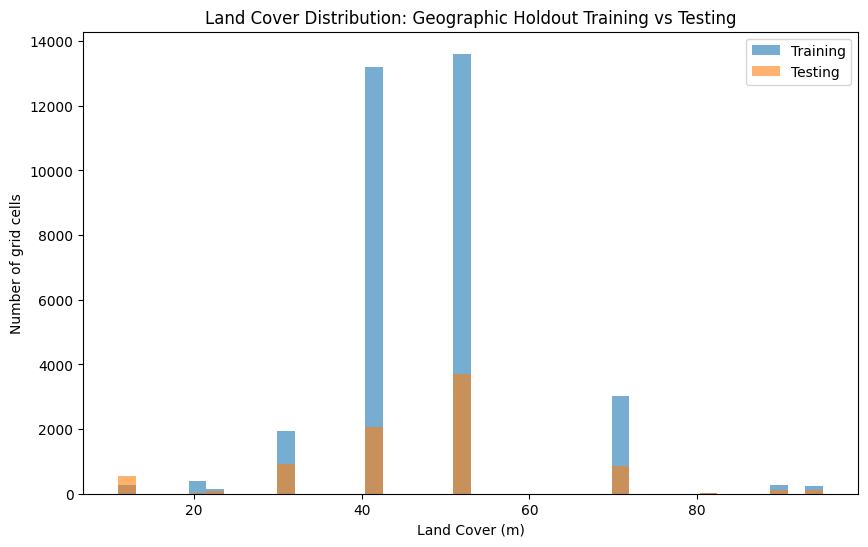

In [53]:
plot_dist(train_df_holdout, test_df_holdout, "nlcd1", "Land Cover", "Geographic Holdout")

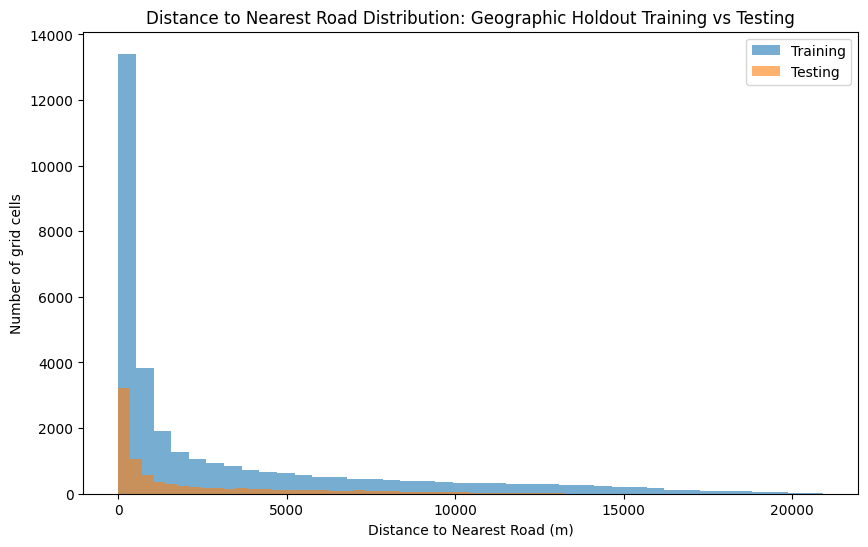

In [54]:
plot_dist(train_df_holdout, test_df_holdout, "distance_road", "Distance to Nearest Road", "Geographic Holdout")

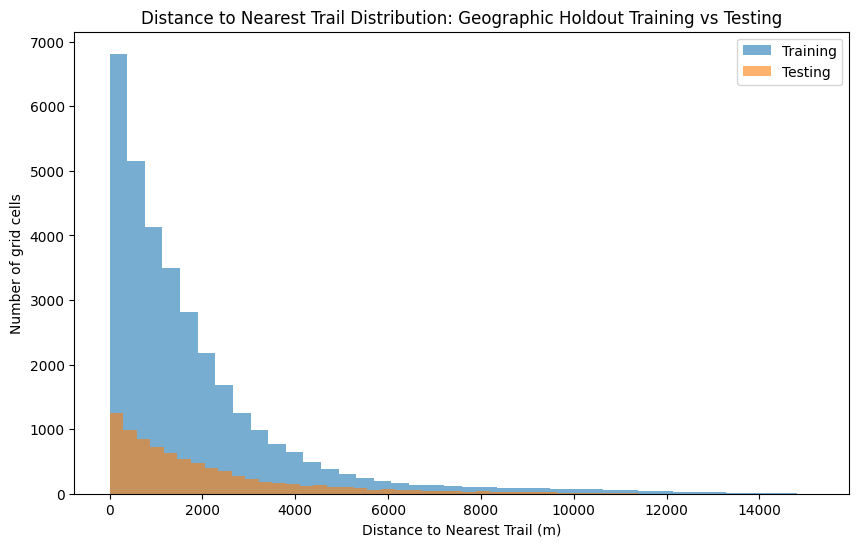

In [55]:
plot_dist(train_df_holdout, test_df_holdout, "distance_path", "Distance to Nearest Trail", "Geographic Holdout")

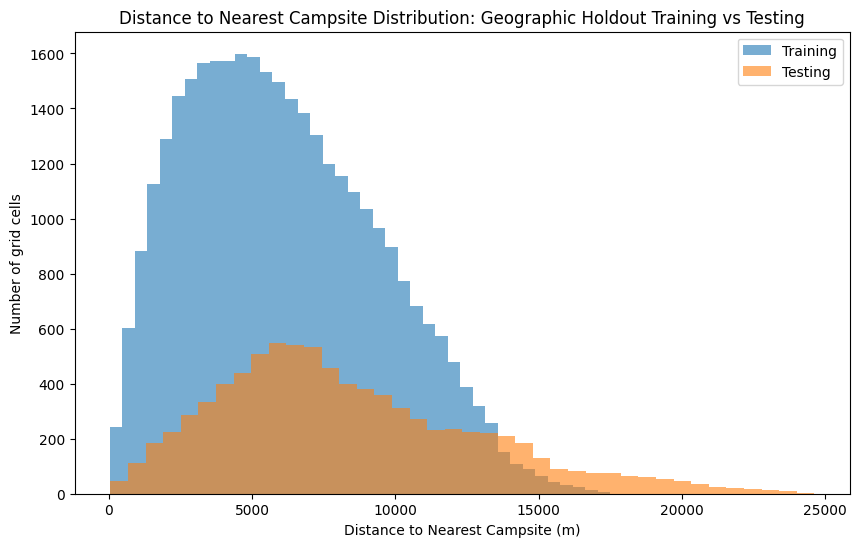

In [56]:
plot_dist(train_df_holdout, test_df_holdout, "distance_campsite", "Distance to Nearest Campsite", "Geographic Holdout")

With the geographic holdout split, several features show greater differences in their distributions between the training and testing sets. Elevation and slope exhibit the most pronounced differences, reflecting the substantial topographic variation between the western and eastern regions of Yosemite National Park. The eastern region includes portions of the high-elevation Sierra Nevada, resulting in different terrain characteristics compared with the western region. These differences illustrate how geographic location can influence the environmental conditions represented in the dataset. This exploratory analysis highlights the importance of examining geographic differences in predictor distributions, as a model trained in one region may encounter a different combination of environmental conditions when applied to another.

###Geographic Holdout with Buffer

In [57]:
#add a 10k buffer so that train and test have no points right next to each other
buffer_size = 5000

train_df_buffer = df[df["x"] < cutoff - buffer_size].copy()

buffer_df = df[
    (df["x"] >= cutoff - buffer_size) &
    (df["x"] < cutoff + buffer_size)
].copy()

test_df_buffer = df[df["x"] >= cutoff + buffer_size].copy()

In [58]:
X_train_buffer = train_df_buffer.drop(columns=['burned'])
y_train_buffer = train_df_buffer['burned']
X_test_buffer = test_df_buffer.drop(columns=['burned'])
y_test_buffer = test_df_buffer['burned']

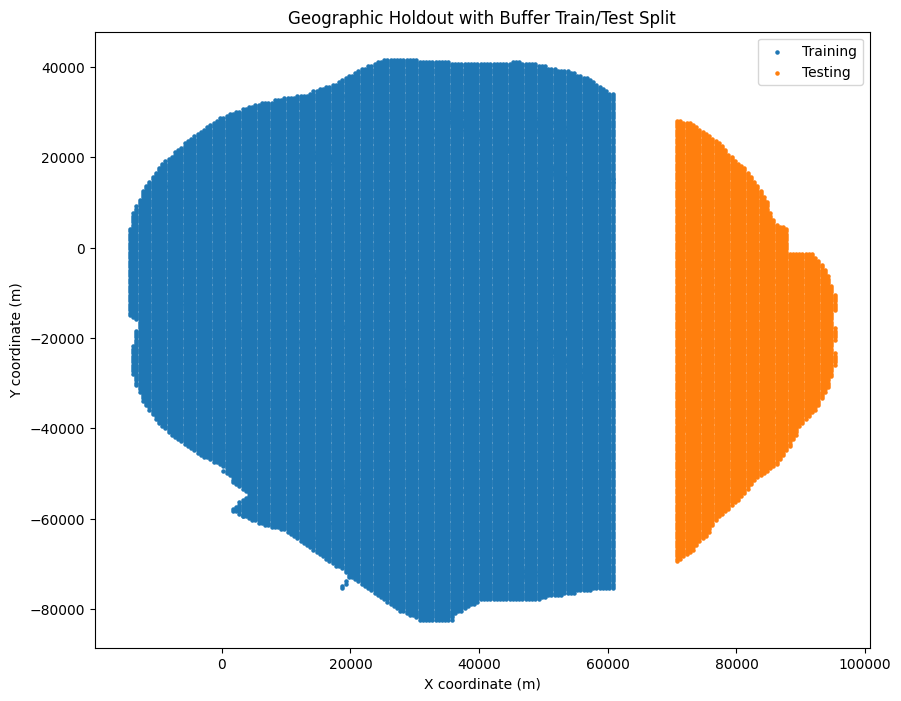

In [59]:
plot_split(train_df_buffer["x"], train_df_buffer["y"], test_df_buffer["x"], test_df_buffer["y"], "Geographic Holdout with Buffer")

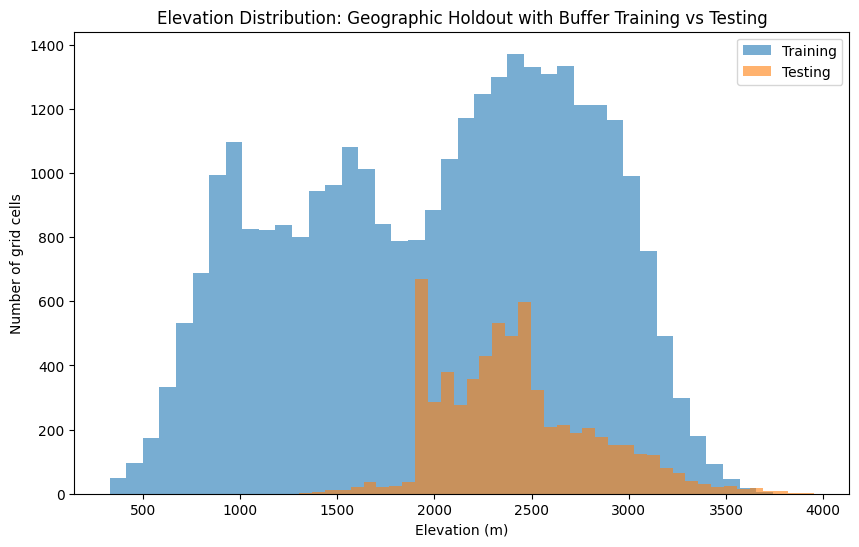

In [60]:
plot_dist(train_df_buffer, test_df_buffer, "elevation1", "Elevation", "Geographic Holdout with Buffer")

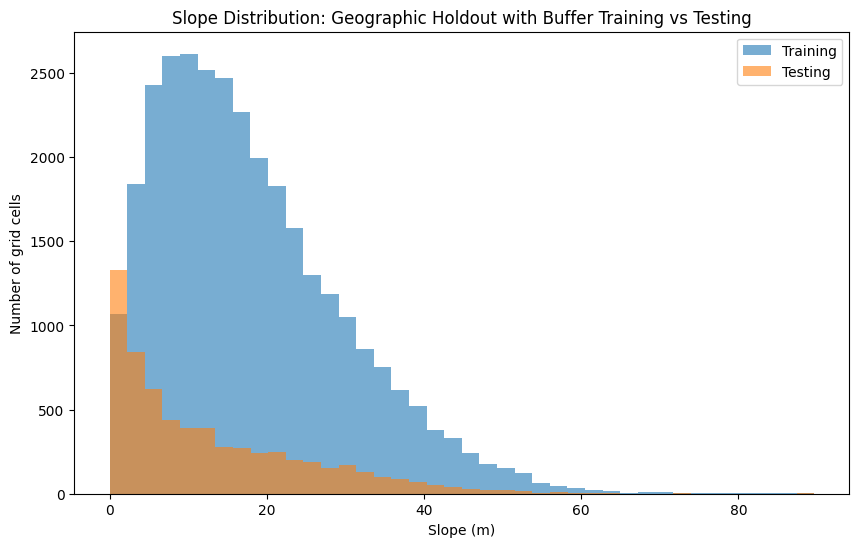

In [61]:
plot_dist(train_df_buffer, test_df_buffer, "slope1", "Slope", "Geographic Holdout with Buffer")

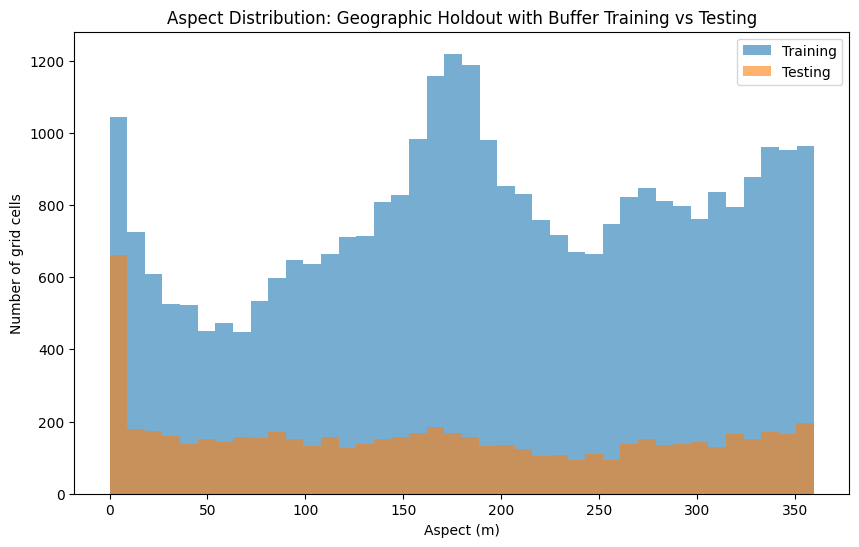

In [62]:
plot_dist(train_df_buffer, test_df_buffer, "aspect1", "Aspect", "Geographic Holdout with Buffer")

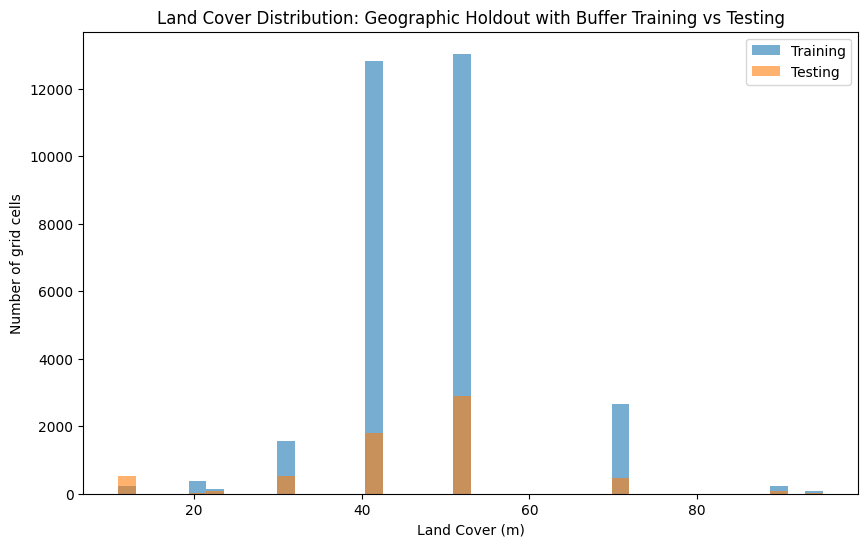

In [63]:
plot_dist(train_df_buffer, test_df_buffer, "nlcd1", "Land Cover", "Geographic Holdout with Buffer")

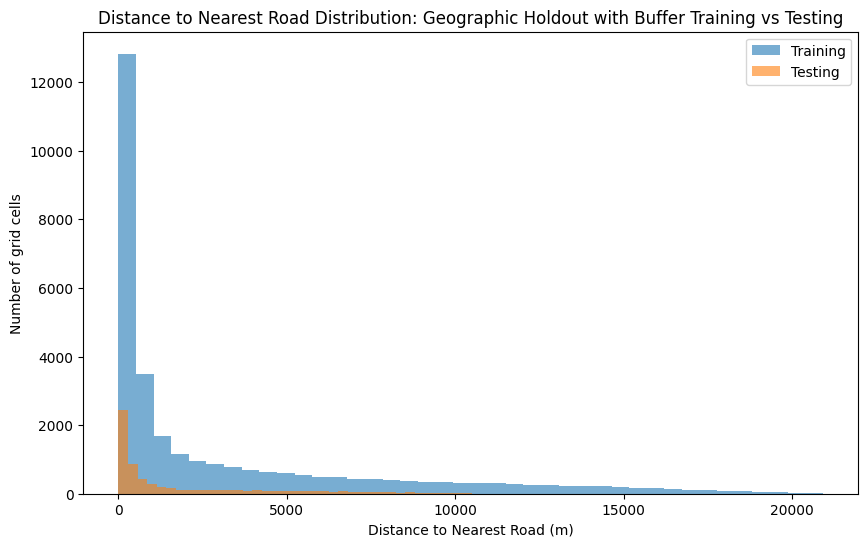

In [64]:
plot_dist(train_df_buffer, test_df_buffer, "distance_road", "Distance to Nearest Road", "Geographic Holdout with Buffer")

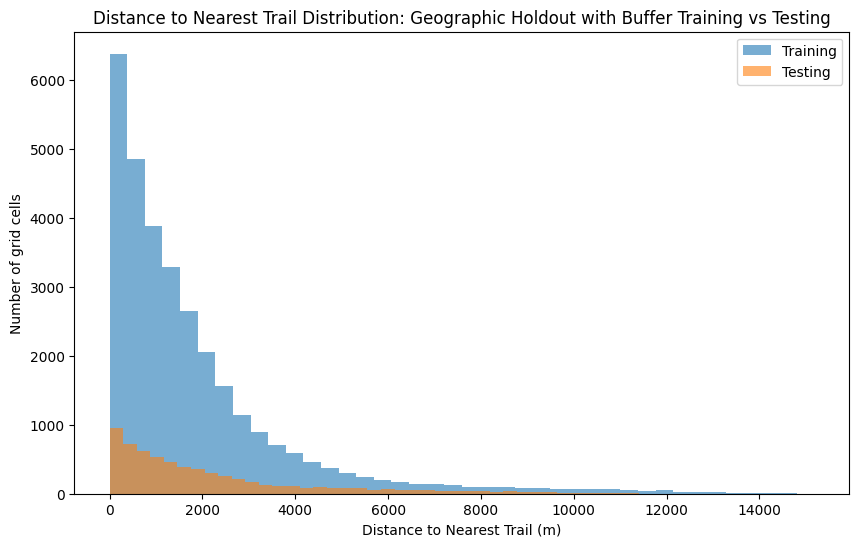

In [65]:
plot_dist(train_df_buffer, test_df_buffer, "distance_path", "Distance to Nearest Trail", "Geographic Holdout with Buffer")

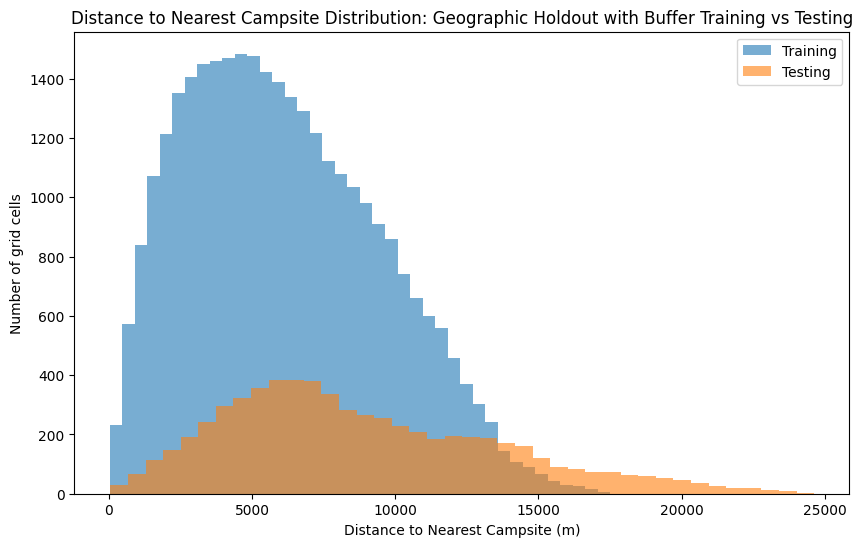

In [66]:
plot_dist(train_df_buffer, test_df_buffer, "distance_campsite", "Distance to Nearest Campsite", "Geographic Holdout with Buffer")

With the addition of a buffer zone around the geographic holdout boundary, the feature distributions remain broadly similar to those observed in the unbuffered geographic holdout. Elevation and slope continue to show differences between the training and testing sets, reflecting the variation in terrain between the western and eastern regions of Yosemite National Park. The buffer excludes observations within 5 km of either side of the boundary, creating greater geographic separation between the two sets and reducing the potential for nearby grid cells to appear across both sets. Although this exclusion does not appear to substantially change the overall feature distributions, it provides a more geographically independent evaluation setup. The extent to which this additional separation affects model performance will be examined in the modeling and validation stage.

##**Model Creation and Training**

Logistic Regression and Random Forest were selected to compare two complementary approaches to binary classification. Logistic Regression provides a simple, interpretable baseline that models relationships between environmental predictors and historical burn occurrence. Random Forest captures nonlinear relationships and interactions between predictors with minimal assumptions about their functional form. Comparing these models helps assess whether a more flexible algorithm improves predictive performance across different spatial train/test strategies.

In [67]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [77]:
def train_model(X_train, y_train, X_test, y_test, model, scaler):
  features = [
    "elevation1",
    "slope1",
    "aspect1",
    "nlcd1",
    "distance_road",
    "distance_path",
    "distance_campsite"
]

  # All Yosemite cells
  X_train_model = X_train[features].copy()
  X_test_model = X_test[features].copy()

  X_train_scaled = scaler.fit_transform(X_train_model)
  X_test_scaled = scaler.transform(X_test_model)

  # Train the model
  model.fit(X_train_scaled, y_train)

  # Predict discrete class labels (0 or 1)
  y_pred = model.predict(X_test_scaled)
  y_prob = model.predict_proba(X_test_scaled)[:, 1]
  balanced_acc = balanced_accuracy_score(y_test, y_pred)
  avg_precision = average_precision_score(y_test, y_prob)


  print("Confusion Matrix:")
  print(confusion_matrix(y_test, y_pred))
  print("\nClassification Report:")
  print(classification_report(y_test, y_pred, output_dict=True))
  print(balanced_acc, avg_precision)

###Logistic Regression

In [78]:
#train with random split
logistic_model_random = LogisticRegression(max_iter=1000)
scaler_random = StandardScaler()
train_model(X_train, y_train, X_test, y_test, logistic_model_random, scaler_random)

Confusion Matrix:
[[4447  573]
 [ 882 2407]]

Classification Report:
{'0': {'precision': 0.8344905235503847, 'recall': 0.8858565737051792, 'f1-score': 0.8594067059619287, 'support': 5020.0}, '1': {'precision': 0.8077181208053691, 'recall': 0.731833384007297, 'f1-score': 0.7679055670760887, 'support': 3289.0}, 'accuracy': 0.824888674930798, 'macro avg': {'precision': 0.8211043221778769, 'recall': 0.8088449788562382, 'f1-score': 0.8136561365190087, 'support': 8309.0}, 'weighted avg': {'precision': 0.8238930470034649, 'recall': 0.824888674930798, 'f1-score': 0.8231872757301887, 'support': 8309.0}}
0.8088449788562382 0.8499807860599498


In [79]:
#train with spatial blocking
logistic_model_spatial = LogisticRegression(max_iter=1000)
scaler_spatial = StandardScaler()
train_model(X_train_blocks, y_train_blocks, X_test_blocks, y_test_blocks, logistic_model_spatial, scaler_spatial)

Confusion Matrix:
[[4337  810]
 [ 787 2045]]

Classification Report:
{'0': {'precision': 0.8464090554254489, 'recall': 0.8426267728774043, 'f1-score': 0.8445136792912082, 'support': 5147.0}, '1': {'precision': 0.7162872154115587, 'recall': 0.7221045197740112, 'f1-score': 0.7191841040970635, 'support': 2832.0}, 'accuracy': 0.799849605213686, 'macro avg': {'precision': 0.7813481354185038, 'recall': 0.7823656463257078, 'f1-score': 0.7818488916941359, 'support': 7979.0}, 'weighted avg': {'precision': 0.8002246901015565, 'recall': 0.799849605213686, 'f1-score': 0.8000302406460376, 'support': 7979.0}}
0.7823656463257078 0.788618064105187


In [80]:
#train with geographic holdout
logistic_model_holdout = LogisticRegression(max_iter=1000)
scaler_holdout = StandardScaler()
train_model(X_train_holdout, y_train_holdout, X_test_holdout, y_test_holdout, logistic_model_holdout, scaler_holdout)

Confusion Matrix:
[[5751  923]
 [ 762 1002]]

Classification Report:
{'0': {'precision': 0.8830032243205896, 'recall': 0.8617021276595744, 'f1-score': 0.8722226435125502, 'support': 6674.0}, '1': {'precision': 0.5205194805194805, 'recall': 0.5680272108843537, 'f1-score': 0.543236649498509, 'support': 1764.0}, 'accuracy': 0.8003081298885992, 'macro avg': {'precision': 0.701761352420035, 'recall': 0.714864669271964, 'f1-score': 0.7077296465055296, 'support': 8438.0}, 'weighted avg': {'precision': 0.8072244468774566, 'recall': 0.8003081298885992, 'f1-score': 0.803446713974654, 'support': 8438.0}}
0.714864669271964 0.4888554064651877


In [81]:
#train with geographic holdout with buffer
logistic_model_buffer = LogisticRegression(max_iter=1000)
scaler_buffer = StandardScaler()
train_model(X_train_buffer, y_train_buffer, X_test_buffer, y_test_buffer, logistic_model_buffer, scaler_buffer)

Confusion Matrix:
[[4335  864]
 [ 543  624]]

Classification Report:
{'0': {'precision': 0.8886838868388683, 'recall': 0.8338141950375072, 'f1-score': 0.8603751116403692, 'support': 5199.0}, '1': {'precision': 0.41935483870967744, 'recall': 0.5347043701799485, 'f1-score': 0.47005649717514125, 'support': 1167.0}, 'accuracy': 0.7789820923656927, 'macro avg': {'precision': 0.6540193627742729, 'recall': 0.6842592826087279, 'f1-score': 0.6652158044077552, 'support': 6366.0}, 'weighted avg': {'precision': 0.8026476004476075, 'recall': 0.7789820923656927, 'f1-score': 0.7888228302892978, 'support': 6366.0}}
0.6842592826087279 0.3916838425010167


###Random Forest

In [82]:
#train with random split
random_forest_model_random = RandomForestClassifier(n_estimators=100, random_state=42)
train_model(X_train, y_train, X_test, y_test, random_forest_model_random, scaler_random)

Confusion Matrix:
[[4685  335]
 [ 501 2788]]

Classification Report:
{'0': {'precision': 0.9033937524103355, 'recall': 0.9332669322709163, 'f1-score': 0.9180873995688811, 'support': 5020.0}, '1': {'precision': 0.8927313480627602, 'recall': 0.8476740650653695, 'f1-score': 0.8696194635059263, 'support': 3289.0}, 'accuracy': 0.8993862077265615, 'macro avg': {'precision': 0.8980625502365478, 'recall': 0.8904704986681429, 'f1-score': 0.8938534315374037, 'support': 8309.0}, 'weighted avg': {'precision': 0.8991731906220126, 'recall': 0.8993862077265615, 'f1-score': 0.8989020533526026, 'support': 8309.0}}
0.8904704986681429 0.9450190360481239


In [83]:
#train with spatial blocking
random_forest_model_spatial = RandomForestClassifier(n_estimators=100, random_state=42)
train_model(X_train_blocks, y_train_blocks, X_test_blocks, y_test_blocks, random_forest_model_spatial, scaler_spatial)

Confusion Matrix:
[[4621  526]
 [ 557 2275]]

Classification Report:
{'0': {'precision': 0.8924295094631132, 'recall': 0.8978045463376725, 'f1-score': 0.8951089588377724, 'support': 5147.0}, '1': {'precision': 0.8122099250267761, 'recall': 0.803319209039548, 'f1-score': 0.8077401029646725, 'support': 2832.0}, 'accuracy': 0.8642687053515478, 'macro avg': {'precision': 0.8523197172449446, 'recall': 0.8505618776886102, 'f1-score': 0.8514245309012225, 'support': 7979.0}, 'weighted avg': {'precision': 0.8639570363306772, 'recall': 0.8642687053515478, 'f1-score': 0.864098982671258, 'support': 7979.0}}
0.8505618776886102 0.8701012989122483


In [84]:
#train with geographic holdout
random_forest_model_holdout = RandomForestClassifier(n_estimators=100, random_state=42)
train_model(X_train_holdout, y_train_holdout, X_test_holdout, y_test_holdout, random_forest_model_holdout, scaler_holdout)

Confusion Matrix:
[[6280  394]
 [ 705 1059]]

Classification Report:
{'0': {'precision': 0.8990694345025053, 'recall': 0.9409649385675757, 'f1-score': 0.9195402298850575, 'support': 6674.0}, '1': {'precision': 0.7288368891947694, 'recall': 0.6003401360544217, 'f1-score': 0.6583773702207025, 'support': 1764.0}, 'accuracy': 0.8697558663190329, 'macro avg': {'precision': 0.8139531618486373, 'recall': 0.7706525373109987, 'f1-score': 0.78895880005288, 'support': 8438.0}, 'weighted avg': {'precision': 0.8634815926059841, 'recall': 0.8697558663190329, 'f1-score': 0.8649430167483044, 'support': 8438.0}}
0.7706525373109987 0.7520756429859363


In [85]:
#train with geographic holdout with buffer
random_forest_model_buffer = RandomForestClassifier(n_estimators=100, random_state=42)
train_model(X_train_buffer, y_train_buffer, X_test_buffer, y_test_buffer, random_forest_model_buffer, scaler_buffer)

Confusion Matrix:
[[4662  537]
 [ 624  543]]

Classification Report:
{'0': {'precision': 0.8819523269012486, 'recall': 0.8967109059434507, 'f1-score': 0.8892703862660944, 'support': 5199.0}, '1': {'precision': 0.5027777777777778, 'recall': 0.4652956298200514, 'f1-score': 0.4833110814419226, 'support': 1167.0}, 'accuracy': 0.8176248821866164, 'macro avg': {'precision': 0.6923650523395132, 'recall': 0.681003267881751, 'f1-score': 0.6862907338540085, 'support': 6366.0}, 'weighted avg': {'precision': 0.8124429491401599, 'recall': 0.8176248821866164, 'f1-score': 0.8148508907069038, 'support': 6366.0}}
0.681003267881751 0.5593446727347927


##**Results and model comparison**

###Logistic Regression metrics

|                    | Precision | Recall | F1   | Accuracy | Balanced Accuracy | PR-AUC |
|--------------------|-----------|--------|------|----------|-------------------|--------|
| Random             |      0.81 |   0.73 | 0.77 |     0.82 |              0.81 |   0.85 |
| Spatial Blocking   |      0.72 |   0.72 | 0.72 |      0.8 |              0.78 |   0.77 |
| Geographic Holdout |      0.52 |   0.57 | 0.54 |      0.8 |              0.71 |   0.49 |
| Buffer             |      0.42 |   0.53 | 0.47 |     0.78 |              0.68 |   0.39 |

###Random Forest metrics

|                    | Precision | Recall | F1   | Accuracy | Balanced Accuracy | PR-AUC |
|--------------------|-----------|--------|------|----------|-------------------|--------|
| Random             |      0.89 |   0.85 | 0.87 |      0.9 |              0.89 |   0.95 |
| Spatial Blocking   |      0.81 |    0.8 | 0.81 |     0.86 |              0.85 |   0.87 |
| Geographic Holdout |      0.73 |    0.6 | 0.66 |     0.87 |              0.77 |   0.75 |
| Buffer             |       0.5 |   0.46 | 0.49 |     0.82 |              0.68 |   0.56 |

###Comparison of split methods
When studying the above metrics, a major takeaway is that random split testing gives the strongest results. With Random Forest, F1 scores drop from .87 to .81 between random split and spatial blocking, then drop dramatically to .54 and .47 with geographic holdout and geographic holdout with buffer. Logistic Regression follows a similar pattern, going from .77 to .72 to .54 to .47.

Randomly splitting nearby grid cells between training and testing may give an overly optimistic estimate of how well the models generalize to geographically distinct areas. Spatially separated testing provides a more demanding test of generalization.

This is consistent with our research question, although these results alone do not prove that spatial autocorrelation is the cause.

The worst results are present with our buffered geographic holdout: Logistic Regression recall is 0.53, meaning it identifies 53% of historically burned test cells. Random Forest recall is 0.46, meaning it identifies 46%. Precision falls to 0.42 for Logistic Regression and 0.50 for Random Forest.

This means both models miss many burned cells, and many cells they label as burned are actually labeled unburned in the test data. The models' ability to identify historical burn occurrence weakens considerably when training and testing are geographically separated. This could reflect differences in terrain, land cover, burn prevalence, or other spatial patterns between the training and test regions.

###Comparison of models
Random Forest has higher F1 scores than Logistic Regression in all four splits, though the difference narrows from 0.10 in the random split to just 0.02 in the buffered split. Random Forest appears better able to capture the relationships in the dataset under most validation conditions. However, its advantage is much smaller when predicting in geographically separated areas. Neither model maintains its random-split performance.

###Model and Split Selection for the Final Map

Random Forest was selected for the final susceptibility map because it achieved higher F1 scores than Logistic Regression across all four validation strategies, as well as higher balanced accuracy and PR-AUC in three of the four splits. These results suggest that Random Forest better captures the relationships between environmental predictors and historical burn occurrence in this dataset.

The buffered geographic holdout was used as the most demanding evaluation of geographic generalization because it separates the training and test regions with a 5 km exclusion buffer. Although Random Forest performance declined substantially under this split, this evaluation provides a more conservative assessment of how well the model performs in geographically distinct areas.

For the final map, the Random Forest model was retrained using all available labeled grid cells and applied to the full study area to estimate the probability of historical burn occurrence. The buffered holdout metrics are retained as the independent evaluation of geographic generalization, while the final map uses the full dataset to maximize the information available for modeling. The resulting map represents modeled historical burn susceptibility rather than a prediction of future wildfire occurrence.

In [87]:
# Predictors used by the model
features = [
    "elevation1",
    "slope1",
    "aspect1",
    "nlcd1",
    "distance_road",
    "distance_path",
    "distance_campsite"
]

# All Yosemite cells
X_all = df[features].copy()
X_all_scaled = scaler_buffer.transform(X_all)

# Predict probability of burned = 1
risk_probability = random_forest_model_buffer.predict_proba(X_all_scaled)[:, 1]
burn_risk = random_forest_model_buffer.predict(X_all_scaled)

# Add predictions to dataframe
df["risk_probability"] = risk_probability
df["burn_risk"] = burn_risk

In [88]:
import geopandas as gpd
from shapely.geometry import box

df["geometry"] = df.apply(
    lambda row: box(
        row["left"],
        row["bottom"],
        row["right"],
        row["top"]
    ),
    axis=1
)

risk_grid = gpd.GeoDataFrame(
    df,
    geometry="geometry",
    crs="EPSG:3310"
)

In [89]:
risk_grid.to_file(
    "yosemite_wildfire_risk.gpkg",
    layer="risk_grid",
    driver="GPKG"
)

In [90]:
from google.colab import files

files.download("/content/yosemite_wildfire_risk.gpkg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###Final Historic Burn Susceptibility Map

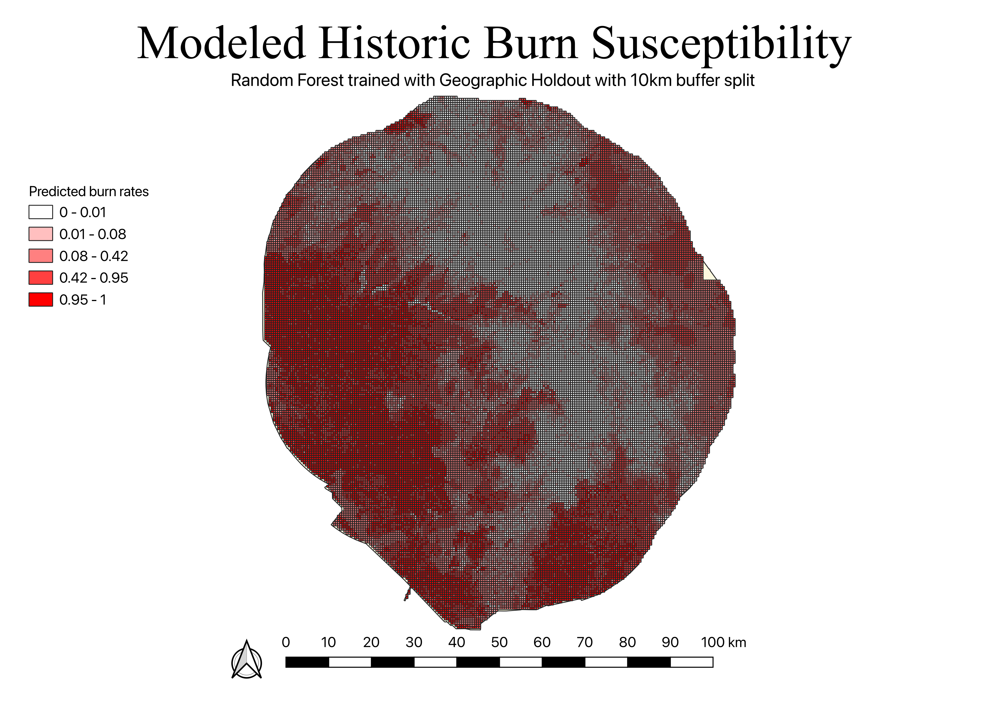

In [91]:
display(Image('buffer_fire_predictions.png', width=500))

##**Conclusions**

This project investigated how spatial train/test splitting strategies affect the evaluation of machine learning models for historical burn susceptibility in Yosemite National Park. Across four validation strategies, Random Forest generally outperformed Logistic Regression, achieving higher F1 scores in every split. However, both models experienced substantial declines in performance as the training and test data became more geographically separated.

Random Forest achieved its strongest results under random splitting, with an F1 score of 0.87, balanced accuracy of 0.89, and PR-AUC of 0.95. Under buffered geographic holdout, its F1 score declined to 0.49, balanced accuracy to 0.68, and PR-AUC to 0.56. These results demonstrate that model performance depends substantially on the validation strategy and suggest that random splitting may provide an overly optimistic estimate of geographic generalization.

The findings highlight the importance of spatially explicit validation when developing machine learning models for environmental applications. Although Random Forest was selected for the final susceptibility map, its reduced performance under geographic holdout indicates that predictions in geographically distinct areas should be interpreted cautiously. Differences in environmental conditions, historical burn prevalence, and spatial patterns may contribute to the observed decline and warrant further investigation.

The final map provides a spatial visualization of modeled historical burn susceptibility across Yosemite National Park. It demonstrates how geospatial data and machine learning can be combined to investigate historical fire patterns, while also illustrating the limitations of evaluating spatial models without accounting for geographic separation. Future work could incorporate additional environmental variables, investigate differences between training and test regions, and evaluate the models using additional historical periods or independent fire data.

Overall, this project demonstrates that **the way a model is evaluated can substantially influence conclusions about its predictive performance**. Accounting for spatial structure is therefore an important consideration when applying machine learning to geographic and environmental data.
